# Evaluation of the Final Model
Notebook 02 froze the final model (XGBoost, trained on Base months 0-3 with 5 seeds, thresholds picked on month 5) and reported its test results on months 6-7 of Base and the 5 variants. This notebook looks at those results more closely: how sure we can be of them, and how they change from month to month.

**Nothing is retrained or re-tuned here.** The frozen model in `outputs/models/` and `configs/final_model.json` is only used to score applications, so nothing in this notebook can steer the model.

Outline:
1. Imports
2. Setup: months, seeds, functions copied from notebook 02, the frozen models
3. Score everything once (saved to a cache), and check the scores
4. Test results over 5 seeds
5. Bootstrap 95% confidence intervals
6. Performance by month
7. Calibration: turning scores into probabilities
8. Different fraud rates
9. Cost-based thresholds
10. Shifting fraud rates: which threshold rule holds up
11. Drift over time
12. Customer groups
13. Summary

## **1. Imports**

In [1]:
import os
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, average_precision_score

from model_loading import load_model   # works on Windows too (see README, Prerequisites)

# Plot settings (same as notebooks 02 and 03)
BLUE = '#2a78d6'
ORANGE = '#eb6834'
GREEN = '#1baf7a'
GREY = '#8a8a8a'
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['grid.alpha'] = 0.3

## **2. Setup**
The same evaluation rules as notebook 02:

| Months | Used for |
|---|---|
| 0-3 | training the models |
| 4 | comparing models and tuning (validation) |
| 5 | picking the threshold for the final model |
| 6-7 | final results, on Base and on all 5 variants |

Base is scored on every month (0-7), so we can see how the model behaves on the months it was trained on as well as on later ones. The variants are scored on months 5-7 only: the model never saw any variant, so months 0-4 of a variant would add little.

In [2]:
DATA_DIR = '../data'
CACHE_FILE = f'{DATA_DIR}/cache/scores.parquet'   # data/ is not committed, so neither is the cache
DATASET_FILES = {
    'base': 'Base.csv',
    'variant_i': 'Variant I.csv',
    'variant_ii': 'Variant II.csv',
    'variant_iii': 'Variant III.csv',
    'variant_iv': 'Variant IV.csv',
    'variant_v': 'Variant V.csv',
}
DATASETS = list(DATASET_FILES)
TARGET = 'fraud_bool'

TRAIN_MONTHS = [0, 1, 2, 3]
VALIDATION_MONTHS = [4]
CALIBRATION_MONTHS = [5]
TEST_MONTHS = [6, 7]
BASE_MONTHS = list(range(8))   # Base is scored on every month
VARIANT_MONTHS = [5, 6, 7]     # the variants on the threshold month and the test months

SEEDS = [0, 1, 2, 3, 4]
TARGET_FPR = 0.05   # at most 5% of genuine applications may be flagged

### **2.1 Functions Copied from Notebook 02**
The metric, the features and the test results are computed exactly as in notebook 02. The functions below are **copies** of notebook 02 (sections 2, 3, 4.2 and 8); if those change, update them here too.

In [3]:
def recall_at_fpr(y_true, scores, target_fpr=TARGET_FPR):
    """Copied from notebook 02, section 2."""
    fpr, tpr, thresholds = roc_curve(y_true, scores)
    i = np.searchsorted(fpr, target_fpr, side='right') - 1   # last point still within the budget
    return tpr[i]


def threshold_at_fpr(y_true, scores, target_fpr=TARGET_FPR):
    """Copied from notebook 02, section 2."""
    fpr, tpr, thresholds = roc_curve(y_true, scores)
    i = np.searchsorted(fpr, target_fpr, side='right') - 1
    return thresholds[i]

In [4]:
MISSING_AS_MINUS_ONE = ['prev_address_months_count', 'current_address_months_count',
                        'bank_months_count', 'session_length_in_minutes',
                        'device_distinct_emails_8w']

CATEGORY_LEVELS = {
    'payment_type': ['AA', 'AB', 'AC', 'AD', 'AE'],
    'employment_status': ['CA', 'CB', 'CC', 'CD', 'CE', 'CF', 'CG'],
    'housing_status': ['BA', 'BB', 'BC', 'BD', 'BE', 'BF', 'BG'],
    'source': ['INTERNET', 'TELEAPP'],
    'device_os': ['linux', 'macintosh', 'other', 'windows', 'x11'],
}
DRIFTING_COLUMNS = ['velocity_6h', 'velocity_24h', 'velocity_4w', 'zip_count_4w']


def preprocess(df, missing_flags=True):
    """Copied from notebook 02, section 3."""
    X = df.copy()
    X['income'] = X['income'].round(1)

    for col in MISSING_AS_MINUS_ONE + ['intended_balcon_amount']:
        if col == 'intended_balcon_amount':
            is_missing = X[col] < 0      # any negative number means missing
        else:
            is_missing = X[col] == -1
        if missing_flags:
            X[f'{col}_missing'] = is_missing.astype(int)
        X.loc[is_missing, col] = np.nan

    for col, levels in CATEGORY_LEVELS.items():
        X[col] = pd.Categorical(X[col], categories=levels)

    return X.drop(columns=['device_fraud_count', 'x1', 'x2'], errors='ignore')


def make_features(df, missing_flags=False, drifting='keep', valid_phones=False, include_age=True):
    """Copied from notebook 02, section 4.2."""
    X = preprocess(df, missing_flags)

    if valid_phones:
        X['valid_phones'] = X['phone_home_valid'] + X['phone_mobile_valid']

    if drifting == 'ratio':
        X['velocity_6h_vs_24h'] = X['velocity_6h'] / X['velocity_24h']
        X['velocity_24h_vs_4w'] = X['velocity_24h'] / X['velocity_4w']
        X['zip_count_vs_velocity_4w'] = X['zip_count_4w'] / X['velocity_4w']
    elif drifting == 'rank':
        for col in DRIFTING_COLUMNS:
            X[f'{col}_month_rank'] = X.groupby('month')[col].rank(pct=True)
    if drifting != 'keep':
        X = X.drop(columns=DRIFTING_COLUMNS)

    if not include_age:
        X = X.drop(columns=['customer_age'])

    return X.drop(columns=[TARGET, 'month'])

In [5]:
def evaluate(y_true, scores, threshold, ages):
    """Copied from notebook 02, section 8."""
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    flagged = scores >= threshold
    fraud = y_true == 1
    genuine = y_true == 0
    is_50_plus = np.asarray(ages) >= 50

    fpr_50_plus = flagged[genuine & is_50_plus].mean()
    fpr_under_50 = flagged[genuine & ~is_50_plus].mean()

    return {
        'recall@5%FPR': recall_at_fpr(y_true, scores),
        'ROC-AUC': roc_auc_score(y_true, scores),
        'PR-AUC': average_precision_score(y_true, scores),
        'recall at threshold': flagged[fraud].mean(),
        'FPR at threshold': flagged[genuine].mean(),
        'precision at threshold': y_true[flagged].mean(),
        'FPR 50+': fpr_50_plus,
        'FPR under 50': fpr_under_50,
        'predictive equality': min(fpr_50_plus, fpr_under_50) / max(fpr_50_plus, fpr_under_50),
    }


METRICS = ['recall@5%FPR', 'ROC-AUC', 'PR-AUC', 'recall at threshold', 'FPR at threshold',
           'precision at threshold', 'FPR 50+', 'FPR under 50', 'predictive equality']

### **2.2 The Frozen Models**
The 5 trained models (one per seed) and their month-5 thresholds, loaded with `load_model` (plain `joblib.load` fails on Windows).

In [6]:
final_model = json.load(open('../configs/final_model.json'))
FEATURES = final_model['features']
thresholds = {int(seed): t for seed, t in final_model['thresholds'].items()}
models = {seed: load_model(f"../outputs/models/{final_model['model']}_seed{seed}.joblib") for seed in SEEDS}

print('Model:', final_model['model'], '| features:', FEATURES)
pd.Series(thresholds, name='threshold (month 5)').rename_axis('seed').to_frame()

Model: xgboost | features: {'missing_flags': True, 'drifting': 'ratio', 'valid_phones': False, 'include_age': True}


,threshold (month 5)
seed,
0,0.474851
1,0.473538
2,0.477038
3,0.476572
4,0.473818


## **3. Score Everything Once**
Every later section works from one table of scores: Base months 0-7 and every variant's months 5-7, with all 5 seeds. Scoring takes about a minute, so the table is saved to `data/cache/scores.parquet` and loaded from there on later runs. Delete the file to score again.

Besides the scores, the table keeps the label, the month, the row number in the original CSV (`row_id`, as in `outputs/predictions/`) and a few applicant columns for later sections.

In [7]:
KEEP_COLUMNS = ['customer_age', 'income', 'employment_status', 'housing_status', 'source',
                'device_os', 'payment_type']


def score_dataset(dataset, months):
    """Scores the given months of one dataset with all 5 frozen models."""
    df = pd.read_csv(f'{DATA_DIR}/{DATASET_FILES[dataset]}')
    part = df[df['month'].isin(months)]
    X = make_features(part, **FEATURES)

    table = pd.DataFrame({
        'dataset': dataset,
        'row_id': part.index.to_numpy(),
        'month': part['month'].to_numpy(),
        'y_true': part[TARGET].to_numpy(),
    })
    for col in KEEP_COLUMNS:
        table[col] = part[col].to_numpy()
    for seed, model in models.items():
        table[f'score_seed{seed}'] = model.predict_proba(X)[:, 1].astype(np.float32)
    return table


if os.path.exists(CACHE_FILE):
    scores = pd.read_parquet(CACHE_FILE)
    print(f'Loaded the cached scores from {CACHE_FILE}')
else:
    start = time.time()
    parts = []
    for dataset in DATASETS:
        months = BASE_MONTHS if dataset == 'base' else VARIANT_MONTHS
        parts.append(score_dataset(dataset, months))
        print(f'{dataset:12s} scored: {len(parts[-1]):,} rows')
    scores = pd.concat(parts, ignore_index=True)
    os.makedirs(os.path.dirname(CACHE_FILE), exist_ok=True)
    scores.to_parquet(CACHE_FILE, index=False)
    print(f'Scored in {(time.time() - start) / 60:.1f} min, saved to {CACHE_FILE}')

scores['dataset'] = pd.Categorical(scores['dataset'], categories=DATASETS)   # keeps the dataset order in tables
SCORE_COLUMNS = [f'score_seed{seed}' for seed in SEEDS]

scores.groupby('dataset').agg(
    rows=('row_id', 'size'),
    first_month=('month', 'min'),
    last_month=('month', 'max'),
    fraud_cases=('y_true', 'sum'),
)

base         scored: 1,000,000 rows


variant_i    scored: 324,332 rows


variant_ii   scored: 324,334 rows


variant_iii  scored: 389,168 rows


variant_iv   scored: 389,168 rows


variant_v    scored: 389,168 rows


Scored in 0.3 min, saved to ../data/cache/scores.parquet


,rows,first_month,last_month,fraud_cases
dataset,,,,
base,1000000,0,7,11029
variant_i,324332,5,7,4289
variant_ii,324334,5,7,4289
variant_iii,389168,5,7,3994
variant_iv,389168,5,7,3994
variant_v,389168,5,7,3994


### **3.1 Checks**
Two checks that the scores really come from the frozen model:
- **Same scores as notebook 02.** On months 6-7, the seed-0 scores must equal the ones notebook 02 saved in `outputs/predictions/` (up to the rounding of the CSV files, about 1e-7).
- **Same thresholds.** Each seed's threshold was picked so that it flags 5% of genuine Base applications in month 5, so it should still do that here.

In [8]:
rows = []
for dataset in DATASETS:
    saved = pd.read_csv(f'../outputs/predictions/{dataset}_test_seed0.csv')
    ours = scores[(scores['dataset'] == dataset) & scores['month'].isin(TEST_MONTHS)]
    merged = saved.merge(ours, on='row_id', how='outer', suffixes=('_saved', ''), indicator=True)
    both = merged['_merge'] == 'both'
    rows.append({
        'dataset': dataset,
        'saved rows': len(saved),
        'our rows': len(ours),
        'rows in both': both.sum(),
        'same month, label and age': bool((merged.loc[both, 'month_saved'] == merged.loc[both, 'month']).all()
                                          & (merged.loc[both, 'y_true_saved'] == merged.loc[both, 'y_true']).all()
                                          & (merged.loc[both, 'customer_age_saved'] == merged.loc[both, 'customer_age']).all()),
        'max abs score difference': (merged.loc[both, 'score'] - merged.loc[both, 'score_seed0']).abs().max(),
    })
prediction_check = pd.DataFrame(rows).set_index('dataset')
prediction_check

,saved rows,our rows,rows in both,"same month, label and age",max abs score difference
dataset,,,,,
base,205011,205011,205011,True,2.980118e-08
variant_i,205010,205010,205010,True,2.979889e-08
variant_ii,205010,205010,205010,True,2.979355e-08
variant_iii,241672,241672,241672,True,2.979965e-08
variant_iv,241672,241672,241672,True,2.979965e-08
variant_v,241672,241672,241672,True,2.980118e-08


In [9]:
month5 = scores[(scores['dataset'] == 'base') & scores['month'].isin(CALIBRATION_MONTHS)]
genuine5 = month5['y_true'] == 0

rows = []
for seed in SEEDS:
    s = month5[f'score_seed{seed}']
    rows.append({
        'seed': seed,
        'threshold (config)': thresholds[seed],
        'threshold recomputed on month 5': threshold_at_fpr(month5['y_true'], s),
        'share of genuine month-5 rows flagged': (s[genuine5] >= thresholds[seed]).mean(),
    })
threshold_check = pd.DataFrame(rows).set_index('seed')
threshold_check

,threshold (config),threshold recomputed on month 5,share of genuine month-5 rows flagged
seed,,,
0,0.474851,0.474851,0.049927
1,0.473538,0.473538,0.049995
2,0.477038,0.477038,0.049783
3,0.476572,0.476572,0.049681
4,0.473818,0.473818,0.049986


**Findings**
- **The scores are the frozen model's.** On months 6-7 every row of every dataset lines up with notebook 02's saved predictions (same rows, months, labels and ages), and the seed-0 scores differ by at most 1.2e-7, which is just the rounding in the CSV files.
- **The thresholds still do their job.** Recomputing each seed's threshold on month 5 gives exactly the value in `configs/final_model.json`, and each one flags 4.97-5.00% of genuine month-5 applications. It is slightly under 5% because the threshold is the last cut-off that stays within the 5% budget.

## **4. Test Results over 5 Seeds**
The main results again, now with the spread over the 5 seeds for every metric: months 6-7 of each dataset, scored by each seed's model with its own frozen threshold. The columns are the same as in notebook 02, section 8:
- **Ranking quality**, recomputed on each dataset: recall at 5% FPR (main metric), ROC-AUC, PR-AUC.
- **The frozen threshold**: recall, FPR and precision with the month-5 threshold applied unchanged.
- **Fairness**: FPR for each age group (50+ vs under 50) and **predictive equality** (lower group FPR / higher group FPR, 1 = equal).

The seed spread only shows how much the model changes with its random seed. It says nothing about how lucky the test set was; that is section 5.

In [10]:
test = scores[scores['month'].isin(TEST_MONTHS)]

rows = []
for dataset, part in test.groupby('dataset'):
    for seed in SEEDS:
        results = evaluate(part['y_true'], part[f'score_seed{seed}'], thresholds[seed], part['customer_age'])
        rows.append({'dataset': dataset, 'seed': seed, **results})
test_results = pd.DataFrame(rows)

test_mean = test_results.groupby('dataset', sort=False)[METRICS].mean()
test_std = test_results.groupby('dataset', sort=False)[METRICS].std()

# mean ± standard deviation over the 5 seeds
test_table = pd.DataFrame({m: [f'{a:.4f} ± {b:.4f}' for a, b in zip(test_mean[m], test_std[m])] for m in METRICS},
                          index=test_mean.index)
test_table

,recall@5%FPR,ROC-AUC,PR-AUC,recall at threshold,FPR at threshold,precision at threshold,FPR 50+,FPR under 50,predictive equality
dataset,,,,,,,,,
base,0.5482 ± 0.0018,0.8937 ± 0.0002,0.1968 ± 0.0009,0.5615 ± 0.0014,0.0531 ± 0.0003,0.1308 ± 0.0007,0.1266 ± 0.0005,0.0389 ± 0.0003,0.3072 ± 0.0027
variant_i,0.5136 ± 0.0033,0.8841 ± 0.0002,0.1775 ± 0.0010,0.5093 ± 0.0034,0.0491 ± 0.0003,0.1287 ± 0.0002,0.1281 ± 0.0010,0.0394 ± 0.0003,0.3076 ± 0.0030
variant_ii,0.5505 ± 0.0009,0.8969 ± 0.0003,0.2090 ± 0.0009,0.6605 ± 0.0035,0.0836 ± 0.0003,0.1011 ± 0.0002,0.1280 ± 0.0006,0.0391 ± 0.0003,0.3054 ± 0.0029
variant_iii,0.4676 ± 0.0019,0.8700 ± 0.0004,0.1258 ± 0.0007,0.5842 ± 0.0029,0.0842 ± 0.0003,0.0715 ± 0.0001,0.1282 ± 0.0006,0.0392 ± 0.0003,0.3058 ± 0.0025
variant_iv,0.4676 ± 0.0019,0.8700 ± 0.0004,0.1258 ± 0.0007,0.5842 ± 0.0029,0.0842 ± 0.0003,0.0715 ± 0.0001,0.1282 ± 0.0006,0.0392 ± 0.0003,0.3058 ± 0.0025
variant_v,0.4835 ± 0.0028,0.8729 ± 0.0001,0.1323 ± 0.0002,0.5934 ± 0.0013,0.0832 ± 0.0003,0.0734 ± 0.0003,0.1264 ± 0.0006,0.0390 ± 0.0003,0.3089 ± 0.0028


**Check against notebook 02 and the README.** Notebook 02 (section 8) printed these means to 4 decimals, and the README reports some of them rounded further. Both are compared with ours below.

In [11]:
# Notebook 02, section 8: the mean over the 5 seeds, as printed there (4 decimals)
NOTEBOOK_02_TABLE = pd.DataFrame([
    [0.5482, 0.8937, 0.1968, 0.5615, 0.0531, 0.1308, 0.1266, 0.0389, 0.3072],
    [0.5136, 0.8841, 0.1775, 0.5093, 0.0491, 0.1287, 0.1281, 0.0394, 0.3076],
    [0.5505, 0.8969, 0.2090, 0.6605, 0.0836, 0.1011, 0.1280, 0.0391, 0.3054],
    [0.4676, 0.8700, 0.1258, 0.5842, 0.0842, 0.0715, 0.1282, 0.0392, 0.3058],
    [0.4676, 0.8700, 0.1258, 0.5842, 0.0842, 0.0715, 0.1282, 0.0392, 0.3058],
    [0.4835, 0.8729, 0.1323, 0.5934, 0.0832, 0.0734, 0.1264, 0.0390, 0.3089],
], index=DATASETS, columns=METRICS)
print('Every number matches notebook 02 (4 decimals):', bool(np.isclose(test_mean.round(4), NOTEBOOK_02_TABLE).all()))

Every number matches notebook 02 (4 decimals): True


In [12]:
# The "Latest test results" table in README.md
README_TABLE = pd.DataFrame({
    'recall@5%FPR': [0.548, 0.514, 0.551, 0.468, 0.468, 0.483],
    'ROC-AUC': [0.894, 0.884, 0.897, 0.870, 0.870, 0.873],
    'FPR at threshold (%)': [5.3, 4.9, 8.4, 8.4, 8.4, 8.3],
    'predictive equality': [0.31] * 6,
}, index=DATASETS)

ours_rounded = pd.DataFrame({
    'recall@5%FPR': test_mean['recall@5%FPR'].round(3),
    'ROC-AUC': test_mean['ROC-AUC'].round(3),
    'FPR at threshold (%)': (test_mean['FPR at threshold'] * 100).round(1),
    'predictive equality': test_mean['predictive equality'].round(2),
}, index=DATASETS)

matches = np.isclose(ours_rounded, README_TABLE)
print('Every number matches the README table:', bool(matches.all()))
exact = {'recall@5%FPR': test_mean['recall@5%FPR'], 'ROC-AUC': test_mean['ROC-AUC'],
         'FPR at threshold (%)': test_mean['FPR at threshold'] * 100,
         'predictive equality': test_mean['predictive equality']}
for i, j in zip(*np.where(~matches)):
    dataset, column = DATASETS[i], README_TABLE.columns[j]
    print(f'  differs: {dataset}, {column}: ours {exact[column].loc[dataset]:.6f}, README {README_TABLE.iloc[i, j]}')
pd.concat({'this notebook': ours_rounded, 'README': README_TABLE}, axis=1)

Every number matches the README table: True


this notebook                                                   \
             recall@5%FPR ROC-AUC FPR at threshold (%) predictive equality   
base                0.548   0.894                  5.3                0.31   
variant_i           0.514   0.884                  4.9                0.31   
variant_ii          0.551   0.897                  8.4                0.31   
variant_iii         0.468   0.870                  8.4                0.31   
variant_iv          0.468   0.870                  8.4                0.31   
variant_v           0.483   0.873                  8.3                0.31   

                  README                                                   
            recall@5%FPR ROC-AUC FPR at threshold (%) predictive equality  
base               0.548   0.894                  5.3                0.31  
variant_i          0.514   0.884                  4.9                0.31  
variant_ii         0.551   0.897                  8.4                0.31  
variant_iii        0.468   0.870                  8.4                0.31  
variant_iv         0.468   0.870                  8.4                0.31  
variant_v          0.483   0.873                  8.3                0.31

**Findings**
- **These are notebook 02's test results again** (notebook 02, section 8), and they reproduce it exactly: all 54 means (6 datasets x 9 metrics) match to 4 decimals. What this section adds is the spread over the 5 seeds for every metric; the confidence intervals are in section 5.
- **They also match the README.** The README used to give Variant V's recall at 5% FPR as 0.484, but the exact value is 0.48348, which rounds to 0.483 (notebook 02's 0.4835 had been rounded a second time). The README now says 0.483, and every number matches.
- **The seed hardly matters.** On Base, recall at 5% FPR is 0.548 ± 0.002, ROC-AUC 0.894 ± 0.0002 and PR-AUC 0.197 ± 0.001. Across all datasets the seed standard deviation of recall at 5% FPR is 0.001-0.003, and of ROC-AUC at most 0.0004.
- **The same age gap appears everywhere.** With the frozen threshold, about 12.6-12.8% of genuine applicants aged 50+ are wrongly flagged against 3.9% of those under 50, so predictive equality is 0.31 on every dataset.
- Variants III and IV give identical numbers, as expected: their test months contain the same applications.

## **5. Bootstrap 95% Confidence Intervals**
The test months are one sample of applications. A different month with different applicants would give somewhat different numbers, and with only about 2,000-2,700 fraud cases per test set, recall can move by a point or two by chance alone. The **bootstrap** estimates how much:

1. Draw a new test set of the same size by resampling applications with replacement (1,000 times).
2. On each resampled test set, compute every metric for each of the 5 seeds and average over the seeds.
3. The 95% confidence interval is the range between the 2.5th and 97.5th percentiles of those 1,000 averages.

So the interval is about **which applications happened to land in the test set**. The seed spread is reported separately in section 4. Every seed sees the same resampled applications.

**How it is made fast.** Recomputing an ROC curve on about 200,000 rows 1,000 times, for 5 seeds and 6 datasets, takes too long. Three tricks make it quick, without changing the result:
- **Poisson weights.** Instead of copying rows, each application gets a random weight (how many times it was drawn), from a Poisson distribution with mean 1. This is the standard large-sample version of resampling with replacement.
- **Sort once.** The scores of each seed are sorted once. For every resample, running totals of the weights of fraud and of all applications down the sorted list give the weighted ROC curve at every cut-off at once. Recall at 5% FPR, ROC-AUC (area under that curve) and PR-AUC (weighted average precision) follow from it. The frozen threshold flags the top of the sorted list, so its recall, FPR, precision and age-group FPRs are weighted counts over that top part.
- **In parallel.** Each dataset (and, in section 6, each month) is bootstrapped on its own CPU core. Each one has its own fixed random seed, so the results do not depend on the order the cores finish in.

When only recall at 5% FPR is needed (section 6), `weighted_recall_at_fpr` is quicker still: it only walks down the top of the sorted list, until the FPR passes 5%.

Both fast versions are first checked against the sklearn version (`evaluate`) with every weight equal to 1, where they must give the same numbers.

In [13]:
from joblib import Parallel, delayed

N_BOOTSTRAP = 1000
BOOTSTRAP_SEED = 4012   # fixed, so the intervals are the same on every run
BATCH = 10              # resamples handled together (limits memory use)
N_JOBS = 6              # CPU cores used at once


def sort_once(scores):
    """Order of the scores from highest to lowest, and the last position of each distinct score."""
    order = np.argsort(scores, kind='mergesort')[::-1]   # as in sklearn's roc_curve
    sorted_scores = scores[order]
    group_ends = np.r_[np.flatnonzero(np.diff(sorted_scores)), len(scores) - 1]
    return order, group_ends


def weighted_metrics(weights, y_true, scores, is_50_plus, threshold, sorted_once):
    """Every metric of `evaluate`, for each row of `weights` (one row = one resample)."""
    order, group_ends = sorted_once
    w = weights[:, order]                     # weights in score order, highest score first
    fraud = y_true[order] == 1
    genuine_50_plus = ~fraud & is_50_plus[order]
    rows = np.arange(len(w))

    # running weighted counts of fraud and of all applications down the sorted list
    fraud_running = np.cumsum(w * fraud, axis=1, dtype=np.int32)
    all_running = np.cumsum(w, axis=1, dtype=np.int32)

    # weighted ROC curve: one point per distinct score (sklearn adds (0, 0) in front)
    tp = fraud_running[:, group_ends].astype(float)
    flagged = all_running[:, group_ends].astype(float)
    fp = flagged - tp
    n_fraud = tp[:, -1]
    n_genuine = fp[:, -1]
    tp_step = np.diff(tp, axis=1, prepend=0)
    fp_step = np.diff(fp, axis=1, prepend=0)

    # recall at 5% FPR: the last point with FPR <= 5% (as recall_at_fpr)
    within_budget = (fp / n_genuine[:, None] <= TARGET_FPR).sum(axis=1)
    recall_at_5 = np.where(within_budget > 0, tp[rows, np.maximum(within_budget - 1, 0)], 0) / n_fraud
    # ROC-AUC: trapezoids under the curve, sum of fp_step * (tp + tp before) / 2
    roc_auc = ((fp_step * tp).sum(axis=1) - (fp_step * tp_step).sum(axis=1) / 2) / (n_fraud * n_genuine)
    # PR-AUC: average precision, sum of recall steps * precision
    precision_curve = np.divide(tp, flagged, out=np.zeros_like(tp), where=flagged > 0)
    pr_auc = (tp_step * precision_curve).sum(axis=1) / n_fraud

    # the frozen threshold flags the top k applications of the sorted list
    k = int((scores >= threshold).sum())
    tp_k = fraud_running[:, k - 1]
    fp_k = all_running[:, k - 1] - tp_k
    fp_50_plus_k = (w[:, :k] * genuine_50_plus[:k]).sum(axis=1)
    genuine_50_plus_total = (w * genuine_50_plus).sum(axis=1)
    fpr_50_plus = fp_50_plus_k / genuine_50_plus_total
    fpr_under_50 = (fp_k - fp_50_plus_k) / (n_genuine - genuine_50_plus_total)

    return {
        'recall@5%FPR': recall_at_5,
        'ROC-AUC': roc_auc,
        'PR-AUC': pr_auc,
        'recall at threshold': tp_k / n_fraud,
        'FPR at threshold': fp_k / n_genuine,
        'precision at threshold': tp_k / (tp_k + fp_k),
        'FPR 50+': fpr_50_plus,
        'FPR under 50': fpr_under_50,
        'predictive equality': np.minimum(fpr_50_plus, fpr_under_50) / np.maximum(fpr_50_plus, fpr_under_50),
    }


def weighted_recall_at_fpr(weights, y_true, sorted_once):
    """Only recall at 5% FPR, for each row of `weights`. Same result as weighted_metrics, but faster:
    it only needs the top of the sorted list, down to where the FPR passes 5%."""
    order, group_ends = sorted_once
    fraud_all = y_true == 1
    n_fraud = (weights * fraud_all).sum(axis=1)
    n_genuine = weights.sum(axis=1) - n_fraud

    # the top of the list: down to where 10% of genuine applications (unweighted) are flagged, which
    # leaves room for the resampling (checked below)
    genuine_sorted = ~fraud_all[order]
    top = np.searchsorted(np.cumsum(genuine_sorted), 2 * TARGET_FPR * genuine_sorted.sum())
    ends = group_ends[group_ends <= top]
    w = weights[:, order[:ends[-1] + 1]]
    tp = np.cumsum(w * fraud_all[order[:ends[-1] + 1]], axis=1, dtype=np.int32)[:, ends].astype(float)
    fp = np.cumsum(w, axis=1, dtype=np.int32)[:, ends] - tp
    fpr = fp / n_genuine[:, None]
    assert (fpr[:, -1] > TARGET_FPR).all(), 'the top of the list is too short'

    within_budget = (fpr <= TARGET_FPR).sum(axis=1)
    rows = np.arange(len(w))
    return np.where(within_budget > 0, tp[rows, np.maximum(within_budget - 1, 0)], 0) / n_fraud


def bootstrap(part, thresholds, main_metric_only=False, n_resamples=N_BOOTSTRAP, rng_seed=BOOTSTRAP_SEED):
    """Every metric (or only recall at 5% FPR), averaged over the 5 seeds, on each of n_resamples
    bootstrap resamples of `part`."""
    y_true = part['y_true'].to_numpy()
    is_50_plus = part['customer_age'].to_numpy() >= 50
    seed_scores = {seed: part[f'score_seed{seed}'].to_numpy() for seed in SEEDS}
    sorted_by_seed = {seed: sort_once(s) for seed, s in seed_scores.items()}
    metrics = ['recall@5%FPR'] if main_metric_only else METRICS

    rng = np.random.default_rng(rng_seed)
    batches = []
    for start in range(0, n_resamples, BATCH):
        # the same resampled applications for every seed
        weights = rng.poisson(1.0, size=(min(BATCH, n_resamples - start), len(part))).astype(np.int32)
        if main_metric_only:
            per_seed = [{'recall@5%FPR': weighted_recall_at_fpr(weights, y_true, sorted_by_seed[seed])}
                        for seed in SEEDS]
        else:
            per_seed = [weighted_metrics(weights, y_true, seed_scores[seed], is_50_plus, thresholds[seed],
                                         sorted_by_seed[seed]) for seed in SEEDS]
        batches.append(pd.DataFrame({m: np.mean([r[m] for r in per_seed], axis=0) for m in metrics}))
    return pd.concat(batches, ignore_index=True)


def bootstrap_parts(parts, main_metric_only=False):
    """bootstrap() on several parts at once, one CPU core each. Returns the results in the same order."""
    columns = ['y_true', 'customer_age'] + SCORE_COLUMNS
    return Parallel(n_jobs=N_JOBS, max_nbytes=None)(delayed(bootstrap)(part[columns], thresholds, main_metric_only)
                                   for part in parts)

**Check against sklearn.** With every weight equal to 1, the fast versions must reproduce `evaluate` (the notebook-02 metrics) for every dataset, seed and metric. The table shows the largest absolute difference.

In [14]:
rows = []
for dataset, part in test.groupby('dataset'):
    y_true = part['y_true'].to_numpy()
    is_50_plus = part['customer_age'].to_numpy() >= 50
    for seed in SEEDS:
        s = part[f'score_seed{seed}'].to_numpy()
        ones = np.ones((1, len(part)), dtype=np.int32)
        fast = weighted_metrics(ones, y_true, s, is_50_plus, thresholds[seed], sort_once(s))
        fast_main = weighted_recall_at_fpr(ones, y_true, sort_once(s))
        exact = test_results[(test_results['dataset'] == dataset) & (test_results['seed'] == seed)].iloc[0]
        rows.append({'dataset': dataset, 'seed': seed, **{m: abs(fast[m][0] - exact[m]) for m in METRICS},
                     'recall@5%FPR (main-metric-only version)': abs(fast_main[0] - exact['recall@5%FPR'])})

difference = pd.DataFrame(rows).set_index(['dataset', 'seed'])
print(f'Largest difference from sklearn over all datasets, seeds and metrics: {difference.to_numpy().max():.1e}')
difference.groupby('dataset', sort=False).max()

Largest difference from sklearn over all datasets, seeds and metrics: 1.1e-16


,recall@5%FPR,ROC-AUC,PR-AUC,recall at threshold,FPR at threshold,precision at threshold,FPR 50+,FPR under 50,predictive equality,recall@5%FPR (main-metric-only version)
dataset,,,,,,,,,,
base,0.0,0.000000e+00,8.326673e-17,0.0,0.0,0.0,0.0,0.0,0.0,0.0
variant_i,0.0,1.110223e-16,2.775558e-17,0.0,0.0,0.0,0.0,0.0,0.0,0.0
variant_ii,0.0,1.110223e-16,8.326673e-17,0.0,0.0,0.0,0.0,0.0,0.0,0.0
variant_iii,0.0,1.110223e-16,2.775558e-17,0.0,0.0,0.0,0.0,0.0,0.0,0.0
variant_iv,0.0,1.110223e-16,2.775558e-17,0.0,0.0,0.0,0.0,0.0,0.0,0.0
variant_v,0.0,1.110223e-16,5.551115e-17,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [15]:
start = time.time()
test_parts = {dataset: part for dataset, part in test.groupby('dataset')}
bootstrap_results = dict(zip(test_parts, bootstrap_parts(test_parts.values())))
print(f'{N_BOOTSTRAP:,} resamples x {len(SEEDS)} seeds x {len(DATASETS)} datasets in {(time.time() - start) / 60:.1f} min')

rows = []
for dataset, resamples in bootstrap_results.items():
    for m in METRICS:
        rows.append({
            'dataset': dataset,
            'metric': m,
            'estimate': test_mean.loc[dataset, m],   # mean over seeds on the real test set (section 4)
            'CI low': resamples[m].quantile(0.025),
            'CI high': resamples[m].quantile(0.975),
        })
ci_table = pd.DataFrame(rows).set_index(['dataset', 'metric'])
ci_table['CI width'] = ci_table['CI high'] - ci_table['CI low']
ci_table.round(4)

1,000 resamples x 5 seeds x 6 datasets in 1.2 min


estimate  CI low  CI high  CI width
dataset     metric                                                     
base        recall@5%FPR              0.5482  0.5292   0.5656    0.0364
            ROC-AUC                   0.8937  0.8881   0.8991    0.0110
            PR-AUC                    0.1968  0.1834   0.2116    0.0283
            recall at threshold       0.5615  0.5435   0.5789    0.0353
            FPR at threshold          0.0531  0.0522   0.0541    0.0018
            precision at threshold    0.1308  0.1249   0.1364    0.0115
            FPR 50+                   0.1266  0.1233   0.1301    0.0069
            FPR under 50              0.0389  0.0380   0.0397    0.0017
            predictive equality       0.3072  0.2964   0.3177    0.0213
variant_i   recall@5%FPR              0.5136  0.4955   0.5304    0.0348
            ROC-AUC                   0.8841  0.8784   0.8902    0.0118
            PR-AUC                    0.1775  0.1641   0.1914    0.0273
            recall at threshold       0.5093  0.4919   0.5255    0.0336
            FPR at threshold          0.0491  0.0482   0.0500    0.0018
            precision at threshold    0.1287  0.1226   0.1344    0.0118
            FPR 50+                   0.1281  0.1236   0.1322    0.0086
            FPR under 50              0.0394  0.0385   0.0403    0.0017
            predictive equality       0.3076  0.2959   0.3205    0.0246
variant_ii  recall@5%FPR              0.5505  0.5327   0.5688    0.0361
            ROC-AUC                   0.8969  0.8910   0.9027    0.0117
            PR-AUC                    0.2090  0.1946   0.2255    0.0309
            recall at threshold       0.6605  0.6440   0.6775    0.0335
            FPR at threshold          0.0836  0.0825   0.0849    0.0023
            precision at threshold    0.1011  0.0968   0.1054    0.0086
            FPR 50+                   0.1280  0.1261   0.1301    0.0040
            FPR under 50              0.0391  0.0379   0.0403    0.0024
            predictive equality       0.3054  0.2954   0.3159    0.0205
variant_iii recall@5%FPR              0.4676  0.4494   0.4856    0.0362
            ROC-AUC                   0.8700  0.8633   0.8763    0.0131
            PR-AUC                    0.1258  0.1145   0.1387    0.0241
            recall at threshold       0.5842  0.5664   0.6022    0.0358
            FPR at threshold          0.0842  0.0831   0.0852    0.0021
            precision at threshold    0.0715  0.0682   0.0749    0.0067
            FPR 50+                   0.1282  0.1265   0.1300    0.0035
            FPR under 50              0.0392  0.0381   0.0402    0.0021
            predictive equality       0.3058  0.2957   0.3149    0.0192
variant_iv  recall@5%FPR              0.4676  0.4487   0.4872    0.0385
            ROC-AUC                   0.8700  0.8633   0.8766    0.0133
            PR-AUC                    0.1258  0.1147   0.1382    0.0236
            recall at threshold       0.5842  0.5645   0.6026    0.0382
            FPR at threshold          0.0842  0.0831   0.0852    0.0021
            precision at threshold    0.0715  0.0681   0.0747    0.0067
            FPR 50+                   0.1282  0.1264   0.1302    0.0038
            FPR under 50              0.0392  0.0382   0.0403    0.0021
            predictive equality       0.3058  0.2965   0.3153    0.0188
variant_v   recall@5%FPR              0.4835  0.4649   0.5023    0.0374
            ROC-AUC                   0.8729  0.8667   0.8793    0.0126
            PR-AUC                    0.1323  0.1202   0.1448    0.0246
            recall at threshold       0.5934  0.5757   0.6124    0.0367
            FPR at threshold          0.0832  0.0821   0.0842    0.0021
            precision at threshold    0.0734  0.0698   0.0767    0.0069
            FPR 50+                   0.1264  0.1245   0.1281    0.0036
            FPR under 50              0.0390  0.0380   0.0402    0.0022
            predictive equality       0.3089  0.2997   0.3187    0.0190

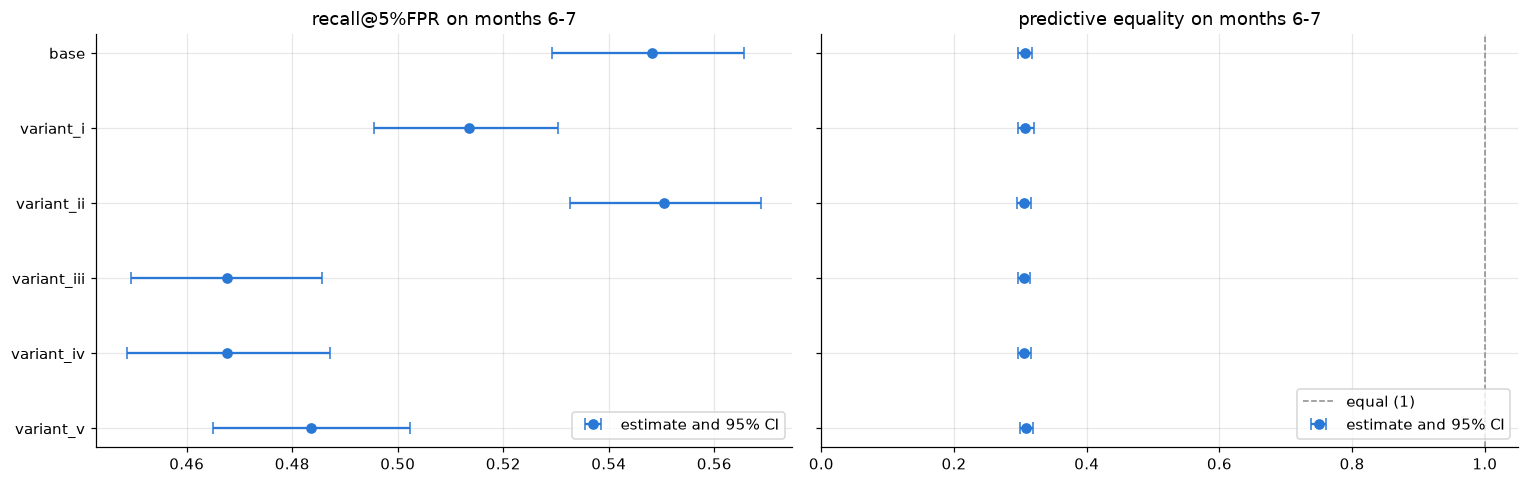

In [16]:
# Forest plot: the estimate and its 95% confidence interval on each dataset
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
positions = np.arange(len(DATASETS))[::-1]   # Base at the top

for ax, metric, reference, reference_label in [
    (axes[0], 'recall@5%FPR', None, None),
    (axes[1], 'predictive equality', 1, 'equal (1)'),
]:
    estimate = ci_table.xs(metric, level='metric').loc[DATASETS]
    ax.errorbar(estimate['estimate'], positions,
                xerr=[estimate['estimate'] - estimate['CI low'], estimate['CI high'] - estimate['estimate']],
                fmt='o', color=BLUE, ecolor=BLUE, capsize=4, markersize=6, label='estimate and 95% CI')
    if reference is not None:
        ax.axvline(reference, color=GREY, linestyle='--', linewidth=1, label=reference_label)
    ax.set_title(f'{metric} on months 6-7')
    ax.legend(loc='lower right')

axes[0].set_yticks(positions)
axes[0].set_yticklabels(DATASETS)
axes[1].set_xlim(0, 1.05)
plt.tight_layout()
plt.show()

**Findings**
- **The test set itself is a much bigger source of uncertainty than the seed.** On Base, recall at 5% FPR is 0.548 with a 95% CI of 0.529-0.566, so about ±0.018, against a seed standard deviation of only 0.002. ROC-AUC is 0.894 (0.888-0.899) and PR-AUC 0.197 (0.183-0.212).
- **Which differences between datasets are real?** The Base and Variant II intervals almost coincide (0.529-0.566 vs 0.533-0.569), so the model does equally well on both. Variants III-V (0.449-0.502) sit clearly below Base, so that drop is not chance. Variant I (0.496-0.530) only just touches Base's interval, so it is probably a little lower too.
- **The unfairness is not chance either.** Predictive equality is 0.307 on Base (0.296-0.318), and every dataset's interval lies between 0.295 and 0.321, far from 1. Genuine applicants aged 50+ are wrongly flagged 3.3 times as often as younger ones on every dataset.
- **The frozen threshold flags slightly more than intended on Base.** Its FPR is 5.31% (5.22-5.41%), so the 5% target lies just outside the interval. On Variants II-V it is 8.3-8.4%, far above 5%.
- Variants III and IV have the same applications, yet their intervals differ slightly (by up to 0.002) because the resampling draws differ. That is the precision of the interval ends themselves.

## **6. Performance by Month**
Each month on its own: Base months 0-7 and the variants' months 5-7. For every month and seed we compute the fraud rate and the section-4 metrics, then average over the 5 seeds. The 95% confidence interval for the main metric (months 5-7) comes from the bootstrap of section 5 (1,000 resamples, averaged over seeds), run on each month separately.

How to read the Base months:
- **0-3, train (in-sample):** the model was trained on these applications, so its scores here are too optimistic.
- **4, validation:** used to choose the model and its settings, so also slightly optimistic.
- **5, threshold month:** the threshold was picked here, so the FPR at the threshold is 5% by construction.
- **6-7, test:** the honest results.

The two questions: does accuracy fall the further we get from the training months (5 to 6 to 7)? And does the frozen threshold keep flagging 5% of genuine applications, or does its FPR drift?

In [17]:
MONTH_ROLES = {0: 'train (in-sample)', 1: 'train (in-sample)', 2: 'train (in-sample)', 3: 'train (in-sample)',
               4: 'validation', 5: 'threshold month', 6: 'test', 7: 'test'}

rows = []
for (dataset, month), part in scores.groupby(['dataset', 'month'], observed=True):
    for seed in SEEDS:
        results = evaluate(part['y_true'], part[f'score_seed{seed}'], thresholds[seed], part['customer_age'])
        rows.append({'dataset': dataset, 'month': month, 'seed': seed,
                     'applications': len(part), 'fraud rate': part['y_true'].mean(), **results})
month_results = pd.DataFrame(rows)

monthly = month_results.drop(columns='seed').groupby(['dataset', 'month'], sort=False).mean()
monthly.insert(0, 'role', [MONTH_ROLES[m] for m in monthly.index.get_level_values('month')])
monthly['applications'] = monthly['applications'].astype(int)

# bootstrap 95% CI of the main metric on months 5-7 (the same code as section 5, one month at a time)
start = time.time()
month_parts = {key: part for key, part in
               scores[scores['month'].isin(VARIANT_MONTHS)].groupby(['dataset', 'month'], observed=True)}
for (dataset, month), resamples in zip(month_parts, bootstrap_parts(month_parts.values(), main_metric_only=True)):
    monthly.loc[(dataset, month), 'recall CI low'] = resamples['recall@5%FPR'].quantile(0.025)
    monthly.loc[(dataset, month), 'recall CI high'] = resamples['recall@5%FPR'].quantile(0.975)
print(f'Monthly bootstrap in {(time.time() - start) / 60:.1f} min')

monthly_columns = ['role', 'applications', 'fraud rate', 'recall@5%FPR', 'recall CI low', 'recall CI high',
                   'ROC-AUC', 'PR-AUC', 'FPR at threshold', 'recall at threshold', 'precision at threshold',
                   'FPR 50+', 'FPR under 50', 'predictive equality']
monthly = monthly[monthly_columns]
monthly.round(4)

Monthly bootstrap in 0.3 min


role  applications  fraud rate  recall@5%FPR  \
dataset     month                                                              
base        0      train (in-sample)        132440      0.0113        0.5519   
            1      train (in-sample)        127620      0.0094        0.6190   
            2      train (in-sample)        136979      0.0087        0.5992   
            3      train (in-sample)        150936      0.0092        0.6408   
            4             validation        127691      0.0114        0.5815   
            5        threshold month        119323      0.0118        0.5425   
            6                   test        108168      0.0134        0.5243   
            7                   test         96843      0.0147        0.5783   
variant_i   5        threshold month        119322      0.0118        0.5130   
            6                   test        108168      0.0134        0.4978   
            7                   test         96842      0.0147        0.5293   
variant_ii  5        threshold month        119324      0.0118        0.5586   
            6                   test        108168      0.0134        0.5448   
            7                   test         96842      0.0147        0.5581   
variant_iii 5        threshold month        147496      0.0091        0.4905   
            6                   test        136092      0.0123        0.4675   
            7                   test        105580      0.0093        0.4663   
variant_iv  5        threshold month        147496      0.0091        0.5577   
            6                   test        136092      0.0123        0.4675   
            7                   test        105580      0.0093        0.4663   
variant_v   5        threshold month        147496      0.0091        0.4730   
            6                   test        136092      0.0123        0.4898   
            7                   test        105580      0.0093        0.4724   

                   recall CI low  recall CI high  ROC-AUC  PR-AUC  \
dataset     month                                                   
base        0                NaN             NaN   0.9054  0.1851   
            1                NaN             NaN   0.9173  0.1683   
            2                NaN             NaN   0.9161  0.1710   
            3                NaN             NaN   0.9325  0.1872   
            4                NaN             NaN   0.9111  0.1869   
            5             0.5159          0.5672   0.8958  0.1898   
            6             0.4959          0.5500   0.8922  0.1796   
            7             0.5515          0.6020   0.8966  0.2196   
variant_i   5             0.4874          0.5386   0.8854  0.1741   
            6             0.4713          0.5236   0.8796  0.1615   
            7             0.5054          0.5537   0.8892  0.1965   
variant_ii  5             0.5339          0.5842   0.9013  0.1904   
            6             0.5184          0.5696   0.8992  0.2055   
            7             0.5342          0.5845   0.8953  0.2148   
variant_iii 5             0.4651          0.5176   0.8783  0.1234   
            6             0.4428          0.4909   0.8711  0.1410   
            7             0.4357          0.4956   0.8667  0.1058   
variant_iv  5             0.5310          0.5836   0.9001  0.1578   
            6             0.4435          0.4901   0.8711  0.1410   
            7             0.4373          0.4959   0.8667  0.1058   
variant_v   5             0.4462          0.5014   0.8737  0.1121   
            6             0.4670          0.5129   0.8725  0.1444   
            7             0.4408          0.5057   0.8720  0.1150   

                   FPR at threshold  recall at threshold  \
dataset     month                                          
base        0                0.0439               0.5236   
            1                0.0434               0.5843   
            2                0.0418               0.5628   
     

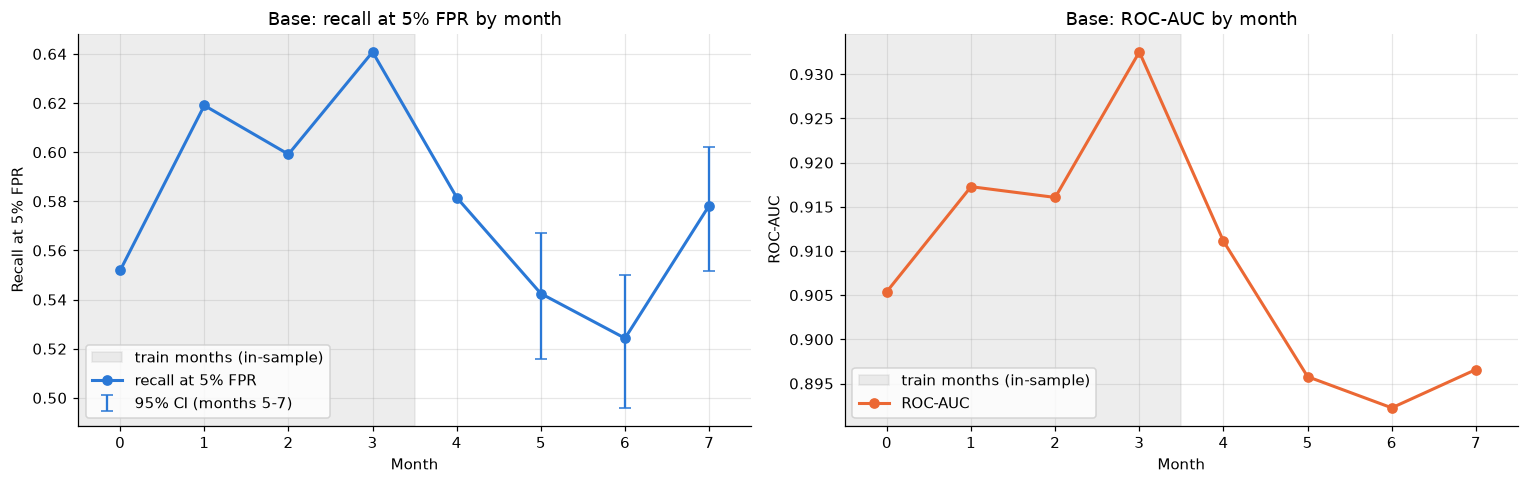

In [18]:
# (a) Base: ranking quality by month, with the training months shaded
base_monthly = monthly.loc['base']
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

ax = axes[0]
ax.axvspan(-0.5, 3.5, color=GREY, alpha=0.15, label='train months (in-sample)')
ax.plot(base_monthly.index, base_monthly['recall@5%FPR'], color=BLUE, marker='o', linewidth=2, label='recall at 5% FPR')
with_ci = base_monthly.dropna(subset=['recall CI low'])
ax.errorbar(with_ci.index, with_ci['recall@5%FPR'],
            yerr=[with_ci['recall@5%FPR'] - with_ci['recall CI low'], with_ci['recall CI high'] - with_ci['recall@5%FPR']],
            fmt='none', ecolor=BLUE, capsize=4, label='95% CI (months 5-7)')
ax.set_title('Base: recall at 5% FPR by month')
ax.set_ylabel('Recall at 5% FPR')
ax.legend(loc='lower left')

ax = axes[1]
ax.axvspan(-0.5, 3.5, color=GREY, alpha=0.15, label='train months (in-sample)')
ax.plot(base_monthly.index, base_monthly['ROC-AUC'], color=ORANGE, marker='o', linewidth=2, label='ROC-AUC')
ax.set_title('Base: ROC-AUC by month')
ax.set_ylabel('ROC-AUC')
ax.legend(loc='lower left')

for ax in axes:
    ax.set_xlabel('Month')
    ax.set_xticks(BASE_MONTHS)
    ax.set_xlim(-0.5, 7.5)
plt.tight_layout()
plt.show()

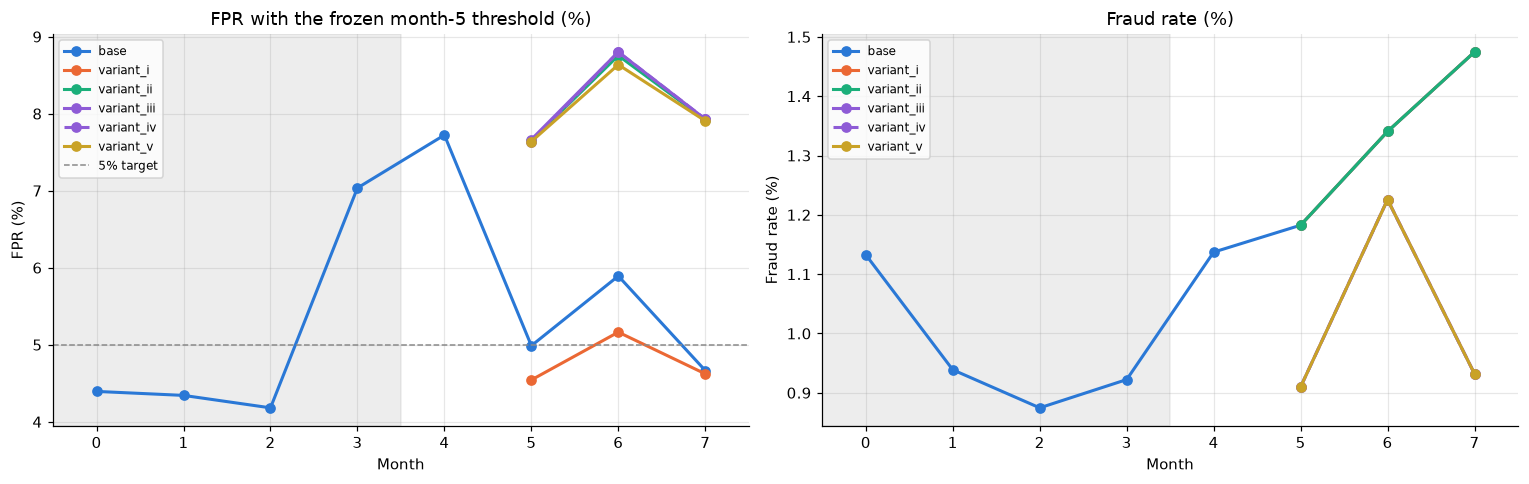

In [19]:
# (b) FPR with the frozen threshold and (c) fraud rate, by month, for every dataset
DATASET_COLOURS = {'base': BLUE, 'variant_i': ORANGE, 'variant_ii': GREEN,
                   'variant_iii': '#8e5bd6', 'variant_iv': '#8e5bd6', 'variant_v': '#c9a227'}
DATASET_STYLES = {'variant_iv': '--'}   # Variant IV's test months are the same applications as Variant III's

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for dataset in DATASETS:
    d = monthly.loc[dataset]
    style = dict(color=DATASET_COLOURS[dataset], linestyle=DATASET_STYLES.get(dataset, '-'), marker='o', linewidth=2,
                 label=dataset)
    axes[0].plot(d.index, d['FPR at threshold'] * 100, **style)
    axes[1].plot(d.index, d['fraud rate'] * 100, **style)

axes[0].axhline(TARGET_FPR * 100, color=GREY, linestyle='--', linewidth=1, label='5% target')
axes[0].set_title('FPR with the frozen month-5 threshold (%)')
axes[0].set_ylabel('FPR (%)')
axes[1].set_title('Fraud rate (%)')
axes[1].set_ylabel('Fraud rate (%)')
for ax in axes:
    ax.axvspan(-0.5, 3.5, color=GREY, alpha=0.15)
    ax.set_xlabel('Month')
    ax.set_xticks(BASE_MONTHS)
    ax.set_xlim(-0.5, 7.5)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Findings**

Does performance drop from month 5 to 6 to 7?
- **No steady drop.** On Base, recall at 5% FPR is 0.543 in month 5, 0.524 in month 6 and 0.578 in month 7, and ROC-AUC is 0.896, 0.892 and 0.897. Month 6 is the weakest month and month 7 the strongest, and their 95% CIs (0.496-0.550 and 0.552-0.602) just fail to overlap. So the months differ, but the model does not get steadily worse the further it is from its training months.
- **Variants I and II show the same dip in month 6** (I: 0.513, 0.498, 0.529; II: 0.559, 0.545, 0.558). Variants III and IV are flat and low on the test months (about 0.47 in both), and Variant V moves within 0.472-0.490.
- **Month-to-month swings are about as large as the differences between datasets.** Even on the training months, recall at 5% FPR ranges from 0.552 (month 0) to 0.641 (month 3), so one month's result should not be read too precisely.
- **The training months look better, as expected.** Recall at 5% FPR is 0.60-0.64 and ROC-AUC 0.916-0.933 on months 1-3, against 0.52-0.58 and 0.892-0.897 on the test months. Month 0 (recall 0.552) is the exception.
- **PR-AUC is highest in month 7 (0.220 on Base)** partly because there is more fraud to find: Base's fraud rate rises from 1.18% in month 5 to 1.34% and 1.47%. Variants I and II have the same fraud rate as Base in every month (their lines overlap), and Variants III-V share theirs (0.91%, 1.23%, 0.93%).

Does the frozen threshold's FPR drift?
- **It moves around, but does not drift in one direction.** On Base the FPR is 4.99% in month 5 (where the threshold was set), 5.89% in month 6 and 4.67% in month 7. Every dataset follows the same up-then-down shape: Variant I goes 4.54%, 5.16%, 4.62%, and Variants II-V go from 7.6-7.7% to 8.6-8.8% and back to 7.9%.
- **Variants II-V are already far above 5% in month 5**, so their high test FPR is not drift: it comes from their different mix of applicants, not from time.
- **The FPR also swings on the earlier Base months**: 4.2-4.4% on months 0-2, but 7.0% on month 3 and 7.7% on month 4. A threshold picked on one month is only roughly right for the next, so in practice it would need checking (and possibly resetting) every month.
- **Predictive equality stays at 0.29-0.32 on every month from 4 to 7** and on every dataset, so the age gap does not change over time. It is lower still (0.23-0.29) on the training months.

## **7. Calibration: Turning Scores into Probabilities**
The model's scores are **not probabilities**: fraud cases were weighted about 26x in training (`scale_pos_weight` = 25.9), so the scores are far too high. The frozen threshold is about 0.475, yet only about 1% of applications are fraud. To read a score as "the chance this application is fraud", it has to be **calibrated**.

Four ways, each applied per seed:

| Method | What it does | Fitted? |
|---|---|---|
| **raw score** | the score as it is (baseline) | no |
| **formula** | undoes the 26x weight in odds space: p = s / (s + w(1 - s)), with w = `scale_pos_weight` | no |
| **Platt** | logistic regression on the logit of the score (2 numbers) | yes |
| **isotonic** | a step function that only goes up, fitted to the fraud rate (`out_of_bounds='clip'`) | yes |

**Only Base month 5 is used to fit anything** (here: Platt and isotonic). Months 6-7 are only used to evaluate. Calibration never changes the order of the scores (except that isotonic merges some of them into ties), so it does not change which applications the frozen threshold flags.

How calibration is measured, on the test months of every dataset:
- **Brier score**: the mean squared difference between the probability and the outcome (0 or 1). Lower is better.
- **Log loss**: punishes confident wrong probabilities heavily. Lower is better. Probabilities are clipped to [1e-6, 1 - 1e-6], so that a single 0 from isotonic does not make it infinite.
- **ECE (expected calibration error)**: sort the applications by probability into 15 bins of equal size, and average the gap between the mean probability and the actual fraud rate in each bin (weighted by bin size). 0 = perfectly honest.
- **Mean predicted probability vs the actual fraud rate**: does the model expect the right amount of fraud overall?

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from scipy.stats import ks_2samp, spearmanr

SCALE_POS_WEIGHT = final_model['params']['scale_pos_weight']
CALIBRATION_METHODS = ['raw score', 'formula', 'Platt', 'isotonic']


def logit(s):
    s = np.clip(np.asarray(s, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(s / (1 - s))


def fit_calibrator(method, y_true, s):
    """Fits one method on (labels, raw scores). Returns a function: raw scores -> probabilities."""
    if method == 'raw score':
        return lambda x: np.asarray(x, dtype=float)
    if method == 'formula':
        # nothing fitted: undo the training weight of the fraud cases in odds space
        def formula(x):
            x = np.asarray(x, dtype=float)
            return x / (x + SCALE_POS_WEIGHT * (1 - x))
        return formula
    if method == 'Platt':
        platt = LogisticRegression(C=1e6).fit(logit(s).reshape(-1, 1), y_true)   # C=1e6: no penalty
        return lambda x: platt.predict_proba(logit(x).reshape(-1, 1))[:, 1]
    if method == 'isotonic':
        isotonic = IsotonicRegression(out_of_bounds='clip', y_min=0, y_max=1).fit(np.asarray(s, dtype=float), y_true)
        return lambda x: isotonic.predict(np.asarray(x, dtype=float))
    raise ValueError(f'unknown method: {method}')


# fitted on Base month 5 only
base_month5 = scores[(scores['dataset'] == 'base') & (scores['month'] == 5)]
calibrators = {(method, seed): fit_calibrator(method, base_month5['y_true'].to_numpy(),
                                              base_month5[f'score_seed{seed}'].to_numpy())
               for method in CALIBRATION_METHODS for seed in SEEDS}

# On month 5 itself: the mean probability of each method vs the actual fraud rate
pd.DataFrame({method: [np.mean([calibrators[(method, seed)](base_month5[f'score_seed{seed}']).mean() for seed in SEEDS])]
              for method in CALIBRATION_METHODS}, index=['mean probability on month 5']).T.assign(
    **{'actual fraud rate (month 5)': base_month5['y_true'].mean()}).round(4)

,mean probability on month 5,actual fraud rate (month 5)
raw score,0.1221,0.0118
formula,0.0092,0.0118
Platt,0.0118,0.0118
isotonic,0.0118,0.0118


### **7.1 Calibration on the Test Months**
Each method is applied, unchanged, to months 6-7 of every dataset. Base is also split into month 6 and month 7, because month 7 has the highest fraud rate (1.47% against 1.18% in month 5, section 6). Mean over the 5 seeds.

In [21]:
N_BINS = 15


def equal_count_bins(p, n_bins=N_BINS):
    """The bin (0 to n_bins - 1) of each probability, with the same number of applications in every bin."""
    order = np.argsort(p, kind='mergesort')
    bins = np.empty(len(p), dtype=int)
    bins[order] = np.arange(len(p)) * n_bins // len(p)
    return bins


def calibration_metrics(y_true, p):
    y = np.asarray(y_true, dtype=float)
    p = np.asarray(p, dtype=float)
    p_clipped = np.clip(p, 1e-6, 1 - 1e-6)
    bins = equal_count_bins(p)
    return {
        'Brier': np.mean((p - y) ** 2),
        'log loss': -np.mean(y * np.log(p_clipped) + (1 - y) * np.log(1 - p_clipped)),
        'ECE': np.abs(np.bincount(bins, weights=p - y, minlength=N_BINS)).sum() / len(y),
        'mean probability': p.mean(),
        'actual fraud rate': y.mean(),
    }


base_test = test[test['dataset'] == 'base']
eval_sets = {
    'base': base_test,
    'base month 6': base_test[base_test['month'] == 6],
    'base month 7': base_test[base_test['month'] == 7],
    **{dataset: test[test['dataset'] == dataset] for dataset in DATASETS[1:]},
}

rows = []
for name, part in eval_sets.items():
    y = part['y_true'].to_numpy()
    for method in CALIBRATION_METHODS:
        for seed in SEEDS:
            p = calibrators[(method, seed)](part[f'score_seed{seed}'].to_numpy())
            rows.append({'data': name, 'method': method, 'seed': seed, **calibration_metrics(y, p)})
calibration_results = pd.DataFrame(rows)
calibration_table = calibration_results.drop(columns='seed').groupby(['data', 'method'], sort=False).mean()
calibration_table.round(4)

Brier  log loss     ECE  mean probability  \
data         method                                                  
base         raw score  0.0439    0.1653  0.1098            0.1238   
             formula    0.0125    0.0550  0.0043            0.0098   
             Platt      0.0124    0.0542  0.0015            0.0125   
             isotonic   0.0124    0.0544  0.0018            0.0126   
base month 6 raw score  0.0474    0.1761  0.1183            0.1317   
             formula    0.0120    0.0532  0.0031            0.0104   
             Platt      0.0120    0.0528  0.0011            0.0134   
             isotonic   0.0120    0.0531  0.0019            0.0135   
base month 7 raw score  0.0401    0.1533  0.1003            0.1150   
             formula    0.0130    0.0570  0.0057            0.0090   
             Platt      0.0128    0.0557  0.0032            0.0115   
             isotonic   0.0128    0.0560  0.0039            0.0115   
variant_i    raw score  0.0417    0.1587  0.1043            0.1183   
             formula    0.0127    0.0570  0.0050            0.0090   
             Platt      0.0126    0.0560  0.0025            0.0115   
             isotonic   0.0126    0.0563  0.0025            0.0116   
variant_ii   raw score  0.0611    0.2134  0.1421            0.1561   
             formula    0.0123    0.0536  0.0005            0.0138   
             Platt      0.0124    0.0541  0.0038            0.0178   
             isotonic   0.0124    0.0545  0.0040            0.0179   
variant_iii  raw score  0.0614    0.2146  0.1439            0.1549   
             formula    0.0103    0.0480  0.0026            0.0133   
             Platt      0.0106    0.0494  0.0063            0.0172   
             isotonic   0.0106    0.0497  0.0065            0.0172   
variant_iv   raw score  0.0614    0.2146  0.1439            0.1549   
             formula    0.0103    0.0480  0.0026            0.0133   
             Platt      0.0106    0.0494  0.0063            0.0172   
             isotonic   0.0106    0.0497  0.0065            0.0172   
variant_v    raw score  0.0608    0.2133  0.1434            0.1544   
             formula    0.0102    0.0475  0.0025            0.0133   
             Platt      0.0105    0.0488  0.0062            0.0171   
             isotonic   0.0105    0.0491  0.0064            0.0172   

                        actual fraud rate  
data         method                        
base         raw score             0.0140  
             formula               0.0140  
             Platt                 0.0140  
             isotonic              0.0140  
base month 6 raw score             0.0134  
             formula               0.0134  
             Platt                 0.0134  
             isotonic              0.0134  
base month 7 raw score             0.0147  
             formula               0.0147  
             Platt                 0.0147  
             isotonic              0.0147  
variant_i    raw score             0.0140  
             formula               0.0140  
             Platt                 0.0140  
             isotonic              0.0140  
variant_ii   raw score             0.0140  
             formula               0.0140  
             Platt                 0.0140  
             isotonic              0.0140  
variant_iii  raw score             0.0110  
             formula               0.0110  
             Platt                 0.0110  
             isotonic              0.0110  
variant_iv   raw score             0.0110  
             formula               0.0110  
             Platt                 0.0110  
             isotonic              0.0110  
variant_v    raw score             0.0110  
             formula               0.0110  
             Platt                 0.0110  
             isotonic              0.0110

**Bootstrap CIs for Brier and ECE on Base.** The same Poisson-weight bootstrap as section 5 (1,000 resamples, the same resampled applications for every seed and method, averaged over seeds). Brier is a weighted mean of squared errors; for ECE the 15 bins are kept as on the real test set and only the weights change, so it is a simple matrix product and takes seconds.

In [22]:
def bootstrap_calibration(y_true, probabilities, n_resamples=N_BOOTSTRAP, rng_seed=BOOTSTRAP_SEED, batch=50):
    """Brier and ECE averaged over seeds, on Poisson-weighted resamples.
    probabilities: {method: [one array per seed]}. Returns {method: DataFrame with one row per resample}."""
    y = np.asarray(y_true, dtype=float)
    columns = {}
    for method, per_seed in probabilities.items():
        squared_errors = np.column_stack([(p - y) ** 2 for p in per_seed])            # n x seeds
        gaps = np.zeros((len(y), len(per_seed) * N_BINS))                             # n x (seeds x bins)
        for i, p in enumerate(per_seed):
            gaps[np.arange(len(y)), i * N_BINS + equal_count_bins(p)] = p - y
        columns[method] = (squared_errors, gaps)

    rng = np.random.default_rng(rng_seed)
    results = {method: [] for method in probabilities}
    for start in range(0, n_resamples, batch):
        w = rng.poisson(1.0, size=(min(batch, n_resamples - start), len(y))).astype(float)
        total = w.sum(axis=1)
        for method, (squared_errors, gaps) in columns.items():
            brier = (w @ squared_errors).mean(axis=1) / total
            bin_gaps = np.abs(w @ gaps).reshape(len(w), -1, N_BINS).sum(axis=2)      # resamples x seeds
            results[method].append(pd.DataFrame({'Brier': brier, 'ECE': bin_gaps.mean(axis=1) / total}))
    return {method: pd.concat(parts, ignore_index=True) for method, parts in results.items()}


start = time.time()
y_base_test = base_test['y_true'].to_numpy()
base_test_probabilities = {method: [calibrators[(method, seed)](base_test[f'score_seed{seed}'].to_numpy())
                                    for seed in SEEDS] for method in CALIBRATION_METHODS}
calibration_bootstrap = bootstrap_calibration(y_base_test, base_test_probabilities)
print(f'Calibration bootstrap in {(time.time() - start) / 60:.1f} min')

rows = []
for method, resamples in calibration_bootstrap.items():
    for metric in ['Brier', 'ECE']:
        rows.append({'method': method, 'metric': metric,
                     'estimate': calibration_table.loc[('base', method), metric],
                     'CI low': resamples[metric].quantile(0.025), 'CI high': resamples[metric].quantile(0.975)})
calibration_ci = pd.DataFrame(rows).set_index(['metric', 'method'])
calibration_ci.round(5)

Calibration bootstrap in 0.1 min


,,estimate,CI low,CI high
metric,method,,,
Brier,raw score,0.04394,0.04347,0.04442
ECE,raw score,0.10978,0.10897,0.11058
Brier,formula,0.01247,0.01201,0.01293
ECE,formula,0.00428,0.00382,0.00483
Brier,Platt,0.01238,0.01194,0.01282
ECE,Platt,0.00153,0.00112,0.00210
Brier,isotonic,0.01239,0.01195,0.01283
ECE,isotonic,0.00175,0.00140,0.00225


**Calibration must not change the ranking.** Raw score, formula and Platt are strictly increasing functions of the score, so ROC-AUC must stay exactly the same. Isotonic is a step function: it gives many scores the same probability (ties), which can change ROC-AUC a little.

In [23]:
rows = []
for seed in SEEDS:
    s = base_test[f'score_seed{seed}'].to_numpy()
    raw_auc = roc_auc_score(y_base_test, s)
    for method in CALIBRATION_METHODS[1:]:
        p = calibrators[(method, seed)](s)
        rows.append({'method': method, 'seed': seed, 'ROC-AUC change': roc_auc_score(y_base_test, p) - raw_auc,
                     'distinct values': len(np.unique(p)), 'distinct raw scores': len(np.unique(s))})
ranking_check = pd.DataFrame(rows).groupby('method', sort=False).agg(
    largest_ROC_AUC_change=('ROC-AUC change', lambda x: x.abs().max()),
    mean_ROC_AUC_change=('ROC-AUC change', 'mean'),
    distinct_values=('distinct values', 'mean'),
    distinct_raw_scores=('distinct raw scores', 'mean'),
)
ranking_check

,largest_ROC_AUC_change,mean_ROC_AUC_change,distinct_values,distinct_raw_scores
method,,,,
formula,0.000000,0.000000,204048.2,204048.2
Platt,0.000000,0.000000,204048.2,204048.2
isotonic,0.000909,-0.000599,159.8,204048.2


### **7.2 Reliability Plots**
Seed 0, Base test months. Each point is one of 15 equal-size bins: its mean predicted probability (x) against the share of fraud actually in it (y). A perfectly calibrated model sits on the diagonal. Both axes are logarithmic, because most applications get a probability well under 1%. Below each panel, a histogram of the probabilities.

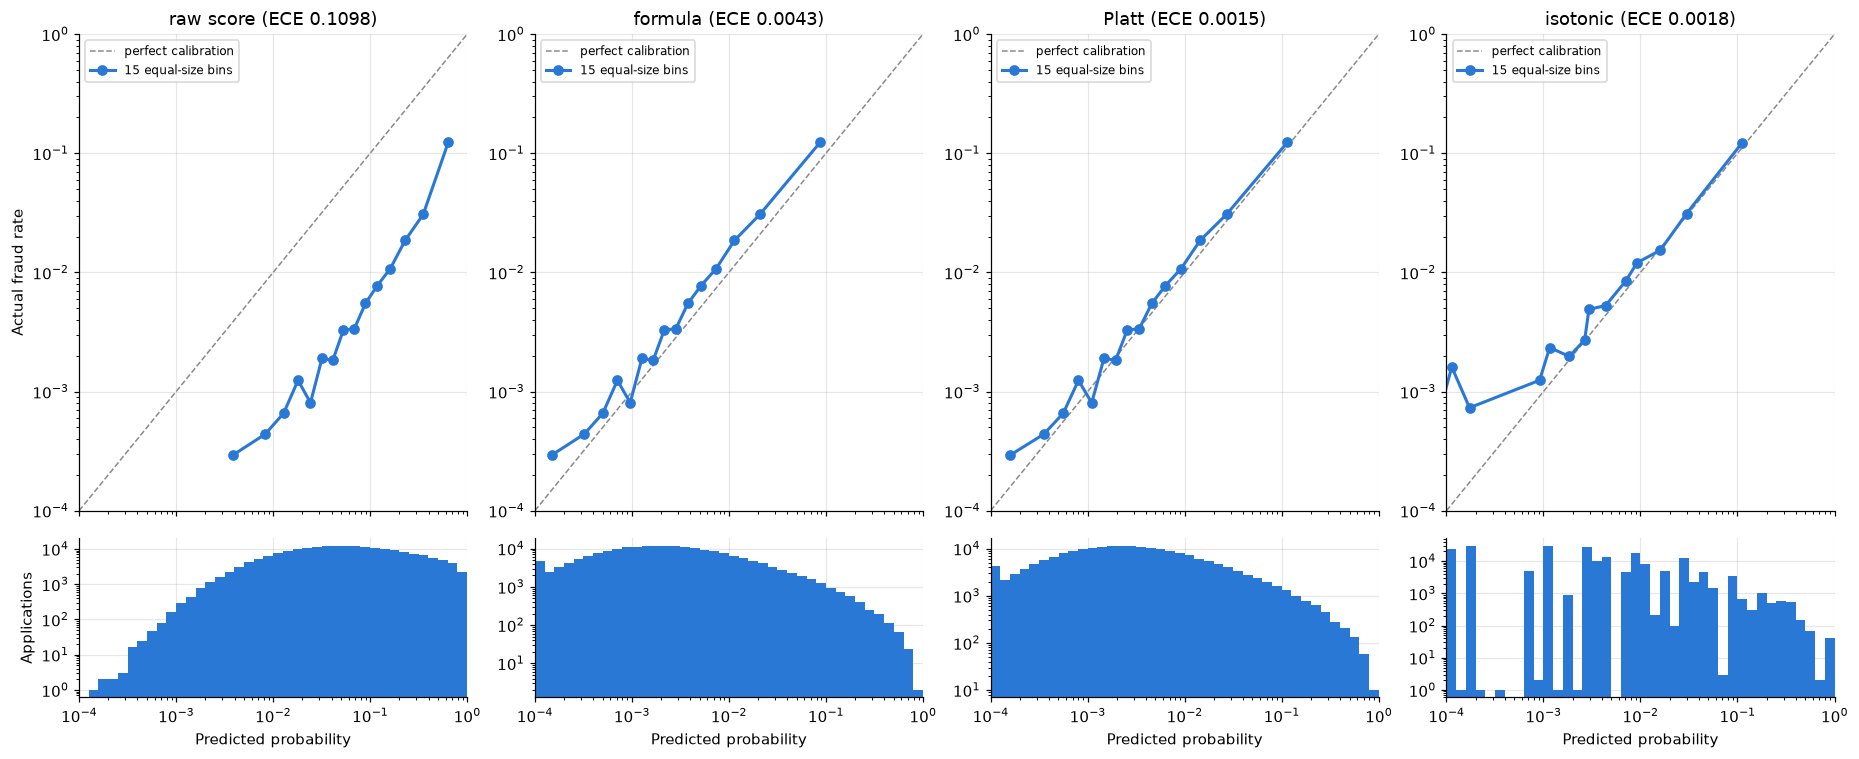

In [24]:
def reliability_points(y_true, p, n_bins=N_BINS):
    """Mean probability and actual fraud rate in each equal-size bin."""
    bins = equal_count_bins(p, n_bins)
    counts = np.bincount(bins, minlength=n_bins)
    return np.bincount(bins, weights=p, minlength=n_bins) / counts, np.bincount(bins, weights=y_true, minlength=n_bins) / counts


fig, axes = plt.subplots(2, 4, figsize=(17, 7), gridspec_kw={'height_ratios': [3, 1]}, sharex='col')
for col, method in enumerate(CALIBRATION_METHODS):
    p = base_test_probabilities[method][0]
    predicted, observed = reliability_points(y_base_test, p)
    shown = (predicted > 0) & (observed > 0)   # a log axis can't show 0
    ax = axes[0, col]
    ax.plot([1e-4, 1], [1e-4, 1], color=GREY, linestyle='--', linewidth=1, label='perfect calibration')
    ax.plot(predicted[shown], observed[shown], color=BLUE, marker='o', linewidth=2, label='15 equal-size bins')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(1e-4, 1)
    ax.set_ylim(1e-4, 1)
    ax.set_title(f'{method} (ECE {calibration_table.loc[("base", method), "ECE"]:.4f})')
    ax.legend(loc='upper left', fontsize=8)

    ax = axes[1, col]
    ax.hist(np.clip(p, 1e-4, 1), bins=np.logspace(-4, 0, 41), color=BLUE)
    ax.set_yscale('log')
    ax.set_xlabel('Predicted probability')
axes[0, 0].set_ylabel('Actual fraud rate')
axes[1, 0].set_ylabel('Applications')
plt.tight_layout()
plt.show()

### **7.3 Choosing a Method**
The method with the lowest Brier score on the Base test months is chosen for the rest of this notebook (raw scores are left out: they are not probabilities). **Note that this choice is made on test data**, so it is a small breach of the "test months only for evaluation" rule. To check that it is not just luck, we also ask what month 5 alone would have chosen: fit on a random half of month 5 and evaluate on the other half (and the other way round), mean over seeds.

In [25]:
base_calibration = calibration_table.loc['base'].drop(index='raw score')
CHOSEN_CALIBRATOR = base_calibration['Brier'].idxmin()
print('Lowest Brier on the Base test months:', CHOSEN_CALIBRATOR)
print('Ranking by Brier:', list(base_calibration['Brier'].sort_values().index))
print('Ranking by ECE:  ', list(base_calibration['ECE'].sort_values().index))

# What month 5 alone would have chosen: fit on one half, evaluate on the other
first_half = np.random.default_rng(BOOTSTRAP_SEED).random(len(base_month5)) < 0.5
rows = []
for fit_half in [first_half, ~first_half]:
    fit_part, eval_part = base_month5[fit_half], base_month5[~fit_half]
    for method in CALIBRATION_METHODS:
        for seed in SEEDS:
            calibrator = fit_calibrator(method, fit_part['y_true'].to_numpy(), fit_part[f'score_seed{seed}'].to_numpy())
            p = calibrator(eval_part[f'score_seed{seed}'].to_numpy())
            rows.append({'method': method, **calibration_metrics(eval_part['y_true'], p)})
month5_split = pd.DataFrame(rows).groupby('method', sort=False)[['Brier', 'log loss', 'ECE']].mean()
calibrated_only = month5_split.drop(index='raw score')
print('Month 5 (half / half) would choose, by Brier:', calibrated_only['Brier'].idxmin(),
      '| by ECE:', calibrated_only['ECE'].idxmin())
month5_split.round(5)

Lowest Brier on the Base test months: Platt
Ranking by Brier: ['Platt', 'isotonic', 'formula']
Ranking by ECE:   ['Platt', 'isotonic', 'formula']


Month 5 (half / half) would choose, by Brier: Platt | by ECE: Platt


,Brier,log loss,ECE
method,,,
raw score,0.04163,0.16048,0.11027
formula,0.01054,0.04748,0.00290
Platt,0.01048,0.04709,0.00119
isotonic,0.01050,0.04730,0.00272


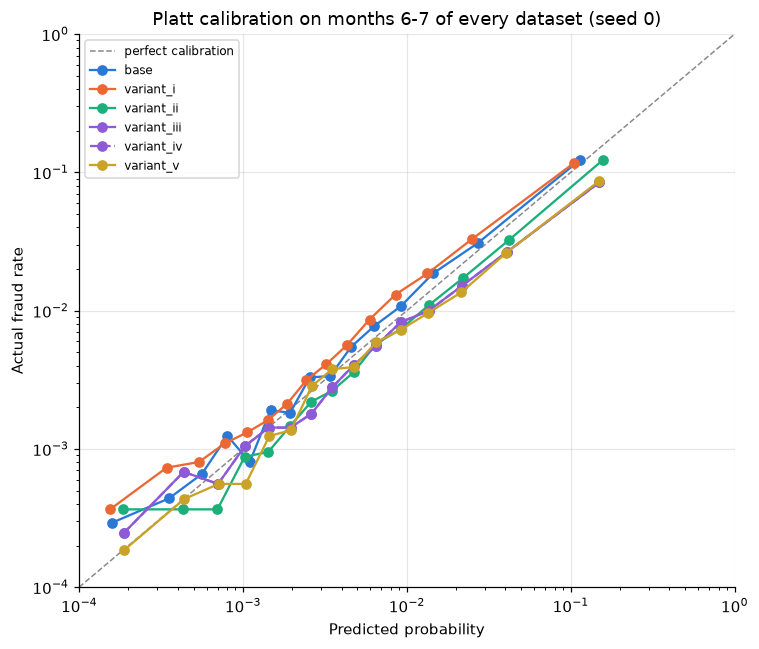

In [26]:
# The chosen method on every dataset (seed 0)
DATASET_COLOURS = {'base': BLUE, 'variant_i': ORANGE, 'variant_ii': GREEN,
                   'variant_iii': '#8e5bd6', 'variant_iv': '#8e5bd6', 'variant_v': '#c9a227'}
DATASET_STYLES = {'variant_iv': '--'}

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([1e-4, 1], [1e-4, 1], color=GREY, linestyle='--', linewidth=1, label='perfect calibration')
for dataset in DATASETS:
    part = eval_sets[dataset]
    p = calibrators[(CHOSEN_CALIBRATOR, 0)](part['score_seed0'].to_numpy())
    predicted, observed = reliability_points(part['y_true'].to_numpy(), p)
    shown = (predicted > 0) & (observed > 0)
    ax.plot(predicted[shown], observed[shown], color=DATASET_COLOURS[dataset],
            linestyle=DATASET_STYLES.get(dataset, '-'), marker='o', linewidth=1.5, label=dataset)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(1e-4, 1)
ax.set_ylim(1e-4, 1)
ax.set_xlabel('Predicted probability')
ax.set_ylabel('Actual fraud rate')
ax.set_title(f'{CHOSEN_CALIBRATOR} calibration on months 6-7 of every dataset (seed 0)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Findings**
- **The raw scores are far from probabilities.** On the Base test months they average 0.124 while only 1.40% of applications are fraud (ECE 0.110). Any calibration fixes most of this.
- **Platt and isotonic are honest on Base; the formula is a little too low.** ECE on the Base test months is 0.0015 for Platt (95% CI 0.0011-0.0021), 0.0018 for isotonic (0.0014-0.0023) and 0.0043 for the formula (0.0038-0.0048). The formula is not fitted to any recent month, and it already gives 0.92% on month 5, where the real fraud rate is 1.18%. Brier scores hardly separate the methods (0.01238, 0.01239 and 0.01247, with overlapping CIs), because most of the Brier score comes from fraud being rare.
- **Platt is chosen.** It has the lowest Brier score and the lowest ECE on the Base test months. That choice was made on test data, but month 5 alone (fit on one half, evaluate on the other) would have chosen Platt too, by both Brier (0.01048) and ECE (0.00119, against 0.00272 for isotonic and 0.00290 for the formula).
- **The ranking is unchanged.** ROC-AUC is exactly the same for the formula and Platt. Isotonic turns about 204,000 distinct scores into about 160 values, and the ties lower ROC-AUC by 0.0006 on average (at most 0.0009).
- **Calibration slips when the fraud rate changes.** Platt was fitted at month 5's 1.18%. On Base month 6 (1.34% fraud) its mean probability is spot on (0.0134), but on month 7 (1.47% fraud) it predicts 0.0115, about a fifth too low, and its ECE about triples, from 0.0011 to 0.0032.
- **On the variants it is too high, except Variant I.** Variant I is fine (mean 0.0115 against 0.0140, ECE 0.0025). On Variants II-V the model gives applicants higher scores (raw mean 0.154-0.156 against 0.124 on Base) without more fraud, so Platt expects 1.71-1.78% fraud where there is 1.10-1.40% (ECE 0.0038-0.0063). The formula happens to look best there (ECE 0.0005-0.0026) only because it is lower everywhere.
- **So the probabilities are honest on data like month 5, but not automatically on new months or a new applicant mix.** The calibrator should be refitted (it takes seconds) whenever recent labelled data arrive.

### **7.4 Save the Calibrator**
So that other notebooks (and the report) can use probabilities instead of raw scores, the chosen calibrator is saved to `configs/calibration.json`, like notebook 02 saves `configs/final_model.json`. Platt needs only two numbers per seed: probability = 1 / (1 + exp(-(a × logit(score) + b))). It is still **fitted on Base month 5 only**.

To use it elsewhere (from the `notebooks/` folder):
```python
from model_loading import calibrate
probabilities = calibrate(scores, seed=0)                    # at the month-5 fraud rate
probabilities = calibrate(scores, seed=0, fraud_rate=0.015)  # corrected to a known new fraud rate (section 8.1)
```
The check below confirms that `calibrate` gives exactly the probabilities used in this notebook.

In [27]:
assert CHOSEN_CALIBRATOR == 'Platt', 'the saved file below assumes Platt'
from model_loading import calibrate

SCORE_CLIP = 1e-6   # same clipping as logit() above
calibration = {
    'method': 'platt',
    'formula': 'p = 1 / (1 + exp(-(a * logit(clip(score)) + b))), with logit(s) = log(s / (1 - s))',
    'score_clip': SCORE_CLIP,
    'fitted_on': {'dataset': 'base', 'months': [5]},
    'fraud_rate_when_fitted': float(base_month5['y_true'].mean()),
    'seeds': {},
}
for seed in SEEDS:
    platt = LogisticRegression(C=1e6).fit(logit(base_month5[f'score_seed{seed}']).reshape(-1, 1), base_month5['y_true'])
    calibration['seeds'][str(seed)] = {'a': float(platt.coef_[0, 0]), 'b': float(platt.intercept_[0])}

with open('../configs/calibration.json', 'w') as f:
    json.dump(calibration, f, indent=2)

# Check: the saved file gives the same probabilities as the calibrator used above, on the Base test months
base_test = scores[(scores['dataset'] == 'base') & scores['month'].isin(TEST_MONTHS)]
difference = max(np.abs(calibrate(base_test[f'score_seed{seed}'], seed) - calibrators[('Platt', seed)](base_test[f'score_seed{seed}'])).max()
                 for seed in SEEDS)
print(f'Largest difference from the notebook calibrator: {difference:.1e}')
print(json.dumps(calibration, indent=2))

Largest difference from the notebook calibrator: 0.0e+00
{
  "method": "platt",
  "formula": "p = 1 / (1 + exp(-(a * logit(clip(score)) + b))), with logit(s) = log(s / (1 - s))",
  "score_clip": 1e-06,
  "fitted_on": {
    "dataset": "base",
    "months": [
      5
    ]
  },
  "fraud_rate_when_fitted": 0.01182504630289215,
  "seeds": {
    "0": {
      "a": 1.0406842828797986,
      "b": -2.9672836790961497
    },
    "1": {
      "a": 1.045064651527383,
      "b": -2.9669626190022402
    },
    "2": {
      "a": 1.0448354064363348,
      "b": -2.9712175551366062
    },
    "3": {
      "a": 1.0467751981288413,
      "b": -2.9724544280419245
    },
    "4": {
      "a": 1.0439654900002182,
      "b": -2.968188442228529
    }
  }
}


## **8. Different Fraud Rates**
The share of fraud changes between months, banks and products. Recall and FPR at a fixed threshold do not depend on the fraud rate (they are measured within the fraud and within the genuine applications), but **precision and the workload do**. With the frozen threshold's recall (TPR) and FPR on the Base test months, for an assumed fraud rate π:

- precision = TPR·π / (TPR·π + FPR·(1 - π))
- alerts per 10,000 applications = 10,000 · (TPR·π + FPR·(1 - π))
- fraud caught per 10,000 = 10,000 · TPR·π
- false alarms per fraud caught = FPR·(1 - π) / (TPR·π)

TPR and FPR are the means over seeds (section 4). The CIs reuse the 1,000 bootstrap resamples of section 5: the same formulas are applied to each resample's TPR and FPR. Nothing here is fitted.

In [28]:
PREVALENCES = [0.001, 0.005, 0.01, 0.011, 0.02, 0.05]   # 1.1% = Base over all months
TPR_TEST = test_mean.loc['base', 'recall at threshold']
FPR_TEST = test_mean.loc['base', 'FPR at threshold']
PREVALENCE_MEASURES = ['precision', 'alerts per 10,000', 'fraud caught per 10,000', 'false alarms per fraud caught']


def at_fraud_rate(tpr, fpr, pi):
    return {
        'precision': tpr * pi / (tpr * pi + fpr * (1 - pi)),
        'alerts per 10,000': 10_000 * (tpr * pi + fpr * (1 - pi)),
        'fraud caught per 10,000': 10_000 * tpr * pi,
        'false alarms per fraud caught': fpr * (1 - pi) / (tpr * pi),
    }


base_resamples = bootstrap_results['base']   # section 5: mean over seeds on each resample
rows = []
for pi in PREVALENCES:
    point = at_fraud_rate(TPR_TEST, FPR_TEST, pi)
    resampled = at_fraud_rate(base_resamples['recall at threshold'], base_resamples['FPR at threshold'], pi)
    row = {'assumed fraud rate': pi}
    for measure in PREVALENCE_MEASURES:
        row[measure] = point[measure]
        row[f'{measure} (CI)'] = f'{resampled[measure].quantile(0.025):.4g} - {resampled[measure].quantile(0.975):.4g}'
    rows.append(row)
prevalence_table = pd.DataFrame(rows).set_index('assumed fraud rate')
print(f'Frozen threshold on the Base test months: TPR {TPR_TEST:.4f}, FPR {FPR_TEST:.4f}')
prevalence_table.round(4)

Frozen threshold on the Base test months: TPR 0.5615, FPR 0.0531


,precision,precision (CI),"alerts per 10,000","alerts per 10,000 (CI)","fraud caught per 10,000","fraud caught per 10,000 (CI)",false alarms per fraud caught,false alarms per fraud caught (CI)
assumed fraud rate,,,,,,,,
0.001,0.0105,0.0101 - 0.01081,536.4071,527.3 - 545.8,5.6150,5.435 - 5.789,94.5309,91.48 - 97.99
0.005,0.0504,0.04873 - 0.05202,556.7419,547.5 - 566,28.0751,27.18 - 28.94,18.8305,18.22 - 19.52
0.010,0.0965,0.09337 - 0.09935,582.1603,572.8 - 591.7,56.1501,54.35 - 57.89,9.3679,9.066 - 9.711
0.011,0.1052,0.1018 - 0.1083,587.2440,577.9 - 596.8,61.7651,59.79 - 63.67,8.5077,8.233 - 8.819
0.020,0.1774,0.1722 - 0.1822,632.9972,622.7 - 643.1,112.3002,108.7 - 115.8,4.6367,4.487 - 4.806
0.050,0.3574,0.3492 - 0.365,785.5078,772.3 - 798.5,280.7505,271.8 - 289.4,1.7979,1.74 - 1.864


### **8.1 Shifting the Calibrated Probabilities**
A calibrated probability is only honest at the fraud rate it was fitted on (Base month 5: 1.18%). If the fraud rate changes to π_new, the probabilities can be corrected without refitting (a **prior shift**): multiply the odds by (π_new / (1 - π_new)) / (π_old / (1 - π_old)), with π_old = the Base month-5 fraud rate. The table shows, on the Base test months with the chosen calibrator (mean over seeds):
- the mean corrected probability (it should be close to the assumed fraud rate),
- the corrected probability of an application exactly at the frozen threshold,
- the share of applications the cost rule of section 9 would flag at R = 10 (probability ≥ 1/11).

The last row shifts to the Base test months' own fraud rate, as a check.

In [29]:
PI_OLD = base_month5['y_true'].mean()


def shift_prior(p, pi_old, pi_new):
    """Corrects probabilities fitted at fraud rate pi_old to fraud rate pi_new."""
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    odds = p / (1 - p) * (pi_new / (1 - pi_new)) / (pi_old / (1 - pi_old))
    return odds / (1 + odds)


targets = [(f'{pi:.1%}', pi) for pi in PREVALENCES] + [('Base test (actual)', y_base_test.mean())]
rows = []
for label, pi in targets:
    per_seed = []
    for seed in SEEDS:
        shifted = shift_prior(base_test_probabilities[CHOSEN_CALIBRATOR][seed], PI_OLD, pi)
        at_threshold = shift_prior(calibrators[(CHOSEN_CALIBRATOR, seed)](np.array([thresholds[seed]])), PI_OLD, pi)[0]
        per_seed.append({'mean corrected probability': shifted.mean(),
                         'probability at the frozen threshold': at_threshold,
                         'share flagged with p >= 1/11': (shifted >= 1 / 11).mean()})
    rows.append({'fraud rate': label, 'assumed rate': pi, **pd.DataFrame(per_seed).mean()})
print(f'Fitted at the Base month-5 fraud rate: {PI_OLD:.4f}')
pd.DataFrame(rows).set_index('fraud rate').round(4)

Fitted at the Base month-5 fraud rate: 0.0118


,assumed rate,mean corrected probability,probability at the frozen threshold,share flagged with p >= 1/11
fraud rate,,,,
0.1%,0.001,0.0012,0.0039,0.0007
0.5%,0.005,0.0058,0.0191,0.0093
1.0%,0.010,0.0108,0.0376,0.0223
1.1%,0.011,0.0118,0.0412,0.0250
2.0%,0.020,0.0198,0.0732,0.0479
5.0%,0.050,0.0421,0.1691,0.1147
Base test (actual),0.014,0.0146,0.0522,0.0329


### **8.2 Checking the Formulas on Real Rows**
The formulas assume that only the fraud rate changes, not what fraud and genuine applications look like. We check this once on real rows: from the Base test months, randomly drop fraud rows to reach a 0.5% fraud rate, or drop genuine rows to reach 2%, then apply the frozen threshold. Mean over 20 random draws and the 5 seeds.

In [30]:
N_DRAWS = 20
rng = np.random.default_rng(BOOTSTRAP_SEED)
fraud_rows = np.flatnonzero(y_base_test == 1)
genuine_rows = np.flatnonzero(y_base_test == 0)

rows = []
for pi in [0.005, 0.02]:
    for draw in range(N_DRAWS):
        if pi < y_base_test.mean():   # fewer fraud rows
            n_fraud = round(pi / (1 - pi) * len(genuine_rows))
            keep = np.r_[genuine_rows, rng.choice(fraud_rows, n_fraud, replace=False)]
        else:                         # fewer genuine rows
            n_genuine = round(len(fraud_rows) * (1 - pi) / pi)
            keep = np.r_[fraud_rows, rng.choice(genuine_rows, n_genuine, replace=False)]
        y = y_base_test[keep]
        for seed in SEEDS:
            flagged = base_test[f'score_seed{seed}'].to_numpy()[keep] >= thresholds[seed]
            caught, false_alarms = (flagged & (y == 1)).sum(), (flagged & (y == 0)).sum()
            rows.append({'fraud rate': pi, 'precision': caught / flagged.sum(),
                         'alerts per 10,000': 10_000 * flagged.mean(),
                         'fraud caught per 10,000': 10_000 * caught / len(y),
                         'false alarms per fraud caught': false_alarms / caught})
empirical = pd.DataFrame(rows).groupby('fraud rate').mean()
analytic = pd.DataFrame({pi: at_fraud_rate(TPR_TEST, FPR_TEST, pi) for pi in [0.005, 0.02]}).T
prevalence_check = pd.concat({'formula': analytic, 'real rows (subsampled)': empirical}, axis=1).swaplevel(axis=1).sort_index(axis=1)
prevalence_check.round(4)

alerts per 10,000                        false alarms per fraud caught  \
                formula real rows (subsampled)                       formula   
0.005          556.7419               556.6815                       18.8305   
0.020          632.9972               633.3218                        4.6367   

                             fraud caught per 10,000                         \
      real rows (subsampled)                 formula real rows (subsampled)   
0.005                18.8830                 28.0751                28.0154   
0.020                 4.6396                112.3002               112.3002   

      precision                         
        formula real rows (subsampled)  
0.005    0.0504                 0.0503  
0.020    0.1774                 0.1773

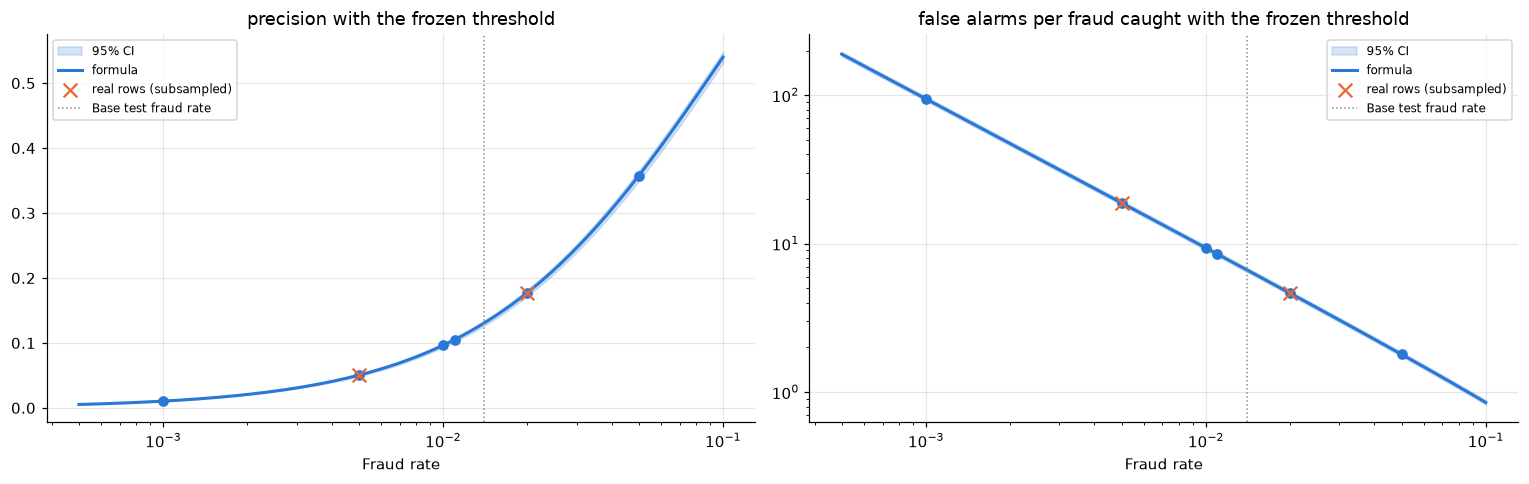

In [31]:
grid = np.logspace(np.log10(0.0005), np.log10(0.1), 200)
curve = at_fraud_rate(TPR_TEST, FPR_TEST, grid)
band = at_fraud_rate(base_resamples['recall at threshold'].to_numpy()[:, None],
                     base_resamples['FPR at threshold'].to_numpy()[:, None], grid[None, :])   # resamples x grid

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, measure in zip(axes, ['precision', 'false alarms per fraud caught']):
    ax.fill_between(grid, np.percentile(band[measure], 2.5, axis=0), np.percentile(band[measure], 97.5, axis=0),
                    color=BLUE, alpha=0.2, label='95% CI')
    ax.plot(grid, curve[measure], color=BLUE, linewidth=2, label='formula')
    ax.scatter(PREVALENCES, [at_fraud_rate(TPR_TEST, FPR_TEST, pi)[measure] for pi in PREVALENCES], color=BLUE, zorder=3)
    ax.scatter(empirical.index, empirical[measure], color=ORANGE, marker='x', s=80, zorder=4, label='real rows (subsampled)')
    ax.axvline(y_base_test.mean(), color=GREY, linestyle=':', linewidth=1, label='Base test fraud rate')
    ax.set_xscale('log')
    ax.set_xlabel('Fraud rate')
    ax.set_title(f'{measure} with the frozen threshold')
    ax.legend(fontsize=8)
axes[1].set_yscale('log')
plt.tight_layout()
plt.show()

**Findings**
- **The same threshold means very different things at different fraud rates.** With recall 0.562 and FPR 5.31% fixed, precision is 1.05% at a fraud rate of 0.1% (95% CI 1.01-1.08%), 9.7% at 1%, 17.7% at 2% and 35.7% at 5%. In false alarms per fraud caught: 95 at 0.1%, 18.8 at 0.5%, 9.4 at 1%, 4.6 at 2% and 1.8 at 5%.
- **The workload barely changes, the catch does.** Alerts per 10,000 applications only go from 536 (0.1% fraud) to 786 (5%), because most alerts are false alarms either way, while the fraud caught goes from 5.6 to 281.
- **The formulas hold on real rows.** Subsampling the Base test months to 0.5% and 2% fraud gives precision 0.0503 and 0.1773 against 0.0504 and 0.1774 from the formula, and 18.88 and 4.64 false alarms per fraud caught against 18.83 and 4.64.
- **The prior-shift correction works.** Shifting Platt's probabilities to the Base test months' own fraud rate (1.40%) gives a mean of 0.0146, against 0.0125 without the correction. It is less exact far from month 5's rate: shifted to 5%, the mean is 0.042.
- **An application right at the frozen threshold is still most likely genuine:** its corrected probability of fraud is 4.1% at a fraud rate of 1.1%, 5.2% at 1.40% and only 16.9% even at 5%.

## **9. Cost-Based Thresholds**
The frozen threshold flags 5% of genuine applications, whatever that costs. A bank would rather pick the threshold with the lowest cost. We use the same cost as notebook 03 (section 6):

> cost = R × missed fraud + false alarms

where R (the cost ratio) is how many false alarms one missed fraud is worth: 5, 10, 20 or 50. Costs are per 10,000 applications.

Three threshold rules, each per seed. **Only Base month 5 is used to choose the thresholds**; months 6-7 are only used to evaluate:
- **frozen 5%-FPR threshold**: notebook 02's threshold (the same for every R).
- **cost search on raw score**: try every cut-off on the month-5 scores and keep the cheapest (`lowest_cost_threshold`, copied from notebook 03).
- **Bayes rule on calibrated probability**: flag when the calibrated probability (section 7's chosen method, fitted on month 5) is at least 1 / (1 + R). If the probabilities are honest, this is the cheapest possible rule: flagging costs (1 - p) false alarms, not flagging costs R·p missed fraud.

In [32]:
COST_RATIOS = [5, 10, 20, 50]
RULES = ['frozen 5%-FPR threshold', 'cost search on raw score', 'Bayes rule on calibrated probability']


def lowest_cost_threshold(y_true, scores, ratio):
    """Copied from notebook 03, section 6.1."""
    order = np.argsort(-scores)
    sorted_scores = scores[order]
    is_fraud = y_true[order] == 1
    # flagging the top k alerts, for every k from 1 to all of them
    false_alarms = np.cumsum(~is_fraud)
    missed_fraud = is_fraud.sum() - np.cumsum(is_fraud)
    costs = ratio * missed_fraud + false_alarms
    best = np.argmin(costs)
    if ratio * is_fraud.sum() <= costs[best]:   # flagging nothing is cheaper
        return np.inf
    return sorted_scores[best]


SCORE_GRID = np.linspace(0, 1, 200_001)


def bayes_score_equivalent(seed, ratio):
    """The lowest raw score that the Bayes rule flags (its threshold on the score scale)."""
    flagged = calibrators[(CHOSEN_CALIBRATOR, seed)](SCORE_GRID) >= 1 / (1 + ratio)
    return SCORE_GRID[flagged].min() if flagged.any() else np.inf


y_month5 = base_month5['y_true'].to_numpy()
search_thresholds = {(ratio, seed): lowest_cost_threshold(y_month5, base_month5[f'score_seed{seed}'].to_numpy(), ratio)
                     for ratio in COST_RATIOS for seed in SEEDS}


def flag(rule, seed, s, ratio):
    """Which applications a threshold rule flags (s = raw scores of one seed)."""
    if rule == RULES[0]:
        return s >= thresholds[seed]
    if rule == RULES[1]:
        return s >= search_thresholds[(ratio, seed)]
    if rule == RULES[2]:
        return calibrators[(CHOSEN_CALIBRATOR, seed)](s) >= 1 / (1 + ratio)
    raise ValueError(rule)


# The thresholds chosen on month 5, as raw scores, and the share of month-5 applications they flag
rows = []
for ratio in COST_RATIOS:
    for seed in SEEDS:
        s5 = base_month5[f'score_seed{seed}'].to_numpy()
        rows.append({'R': ratio, 'seed': seed,
                     'frozen threshold': thresholds[seed],
                     'cost search threshold': search_thresholds[(ratio, seed)],
                     'Bayes rule (as a score)': bayes_score_equivalent(seed, ratio),
                     **{f'month-5 alert rate: {rule}': flag(rule, seed, s5, ratio).mean() for rule in RULES}})
pd.DataFrame(rows).drop(columns='seed').groupby('R').mean().round(4)

,frozen threshold,cost search threshold,Bayes rule (as a score),month-5 alert rate: frozen 5%-FPR threshold,month-5 alert rate: cost search on raw score,month-5 alert rate: Bayes rule on calibrated probability
R,,,,,,
5,0.4752,0.7833,0.7862,0.0557,0.0104,0.0101
10,0.4752,0.6809,0.6544,0.0557,0.0207,0.0239
20,0.4752,0.5132,0.4937,0.0557,0.0476,0.0517
50,0.4752,0.2572,0.2885,0.0557,0.1390,0.1203


In [33]:
def threshold_results(y_true, flagged, is_50_plus, ratio):
    """Cost and error rates of one set of flags."""
    fraud = y_true == 1
    genuine = ~fraud
    fpr_50_plus = flagged[genuine & is_50_plus].mean()
    fpr_under_50 = flagged[genuine & ~is_50_plus].mean()
    missed, false_alarms = (fraud & ~flagged).sum(), (genuine & flagged).sum()
    return {
        'cost per 10,000': 10_000 * (ratio * missed + false_alarms) / len(y_true),
        'recall': flagged[fraud].mean(),
        'FPR': flagged[genuine].mean(),
        'precision': y_true[flagged].mean() if flagged.any() else np.nan,
        'alert rate': flagged.mean(),
        'FPR 50+': fpr_50_plus,
        'FPR under 50': fpr_under_50,
        'predictive equality': min(fpr_50_plus, fpr_under_50) / max(fpr_50_plus, fpr_under_50),
    }


rows = []
for dataset in DATASETS:
    part = eval_sets[dataset]
    y = part['y_true'].to_numpy()
    is_50_plus = part['customer_age'].to_numpy() >= 50
    for seed in SEEDS:
        s = part[f'score_seed{seed}'].to_numpy()
        for ratio in COST_RATIOS:
            for rule in RULES:
                rows.append({'dataset': dataset, 'R': ratio, 'rule': rule, 'seed': seed,
                             **threshold_results(y, flag(rule, seed, s, ratio), is_50_plus, ratio)})
cost_results = pd.DataFrame(rows)
cost_table = cost_results.drop(columns='seed').groupby(['dataset', 'R', 'rule'], sort=False).mean()

# Base test months, every measure
cost_table.loc['base'].round(4)

cost per 10,000  recall     FPR  \
R  rule                                                                    
5  frozen 5%-FPR threshold                      831.6529  0.5615  0.0531   
   cost search on raw score                     620.6594  0.2401  0.0089   
   Bayes rule on calibrated probability         621.3910  0.2355  0.0086   
10 frozen 5%-FPR threshold                     1139.4413  0.5615  0.0531   
   cost search on raw score                    1085.9222  0.3591  0.0189   
   Bayes rule on calibrated probability        1077.1812  0.3875  0.0220   
20 frozen 5%-FPR threshold                     1755.0180  0.5615  0.0531   
   cost search on raw score                    1780.8801  0.5240  0.0451   
   Bayes rule on calibrated probability        1767.9734  0.5428  0.0491   
50 frozen 5%-FPR threshold                     3601.7482  0.5615  0.0531   
   cost search on raw score                    3070.1670  0.7554  0.1372   
   Bayes rule on calibrated probability        3097.6289  0.7259  0.1191   

                                         precision  alert rate  FPR 50+  \
R  rule                                                                   
5  frozen 5%-FPR threshold                  0.1308      0.0603   0.1266   
   cost search on raw score                 0.2799      0.0121   0.0267   
   Bayes rule on calibrated probability     0.2805      0.0118   0.0260   
10 frozen 5%-FPR threshold                  0.1308      0.0603   0.1266   
   cost search on raw score                 0.2147      0.0237   0.0524   
   Bayes rule on calibrated probability     0.2002      0.0272   0.0597   
20 frozen 5%-FPR threshold                  0.1308      0.0603   0.1266   
   cost search on raw score                 0.1421      0.0518   0.1099   
   Bayes rule on calibrated probability     0.1359      0.0561   0.1184   
50 frozen 5%-FPR threshold                  0.1308      0.0603   0.1266   
   cost search on raw score                 0.0727      0.1459   0.2726   
   Bayes rule on calibrated probability     0.0799      0.1276   0.2444   

                                         FPR under 50  predictive equality  
R  rule                                                                     
5  frozen 5%-FPR threshold                     0.0389               0.3072  
   cost search on raw score                    0.0054               0.2017  
   Bayes rule on calibrated probability        0.0052               0.2014  
10 frozen 5%-FPR threshold                     0.0389               0.3072  
   cost search on raw score                    0.0124               0.2354  
   Bayes rule on calibrated probability        0.0147               0.2469  
20 frozen 5%-FPR threshold                     0.0389               0.3072  
   cost search on raw score                    0.0325               0.2959  
   Bayes rule on calibrated probability        0.0357               0.3016  
50 frozen 5%-FPR threshold                     0.0389               0.3072  
   cost search on raw score                    0.1110               0.4072  
   Bayes rule on calibrated probability        0.0948               0.3877

In [34]:
# Cost per 10,000 applications on every dataset (rows) for each cost ratio R (columns)
cost_table['cost per 10,000'].unstack('R').round(1)

R                                                     5       10      20  \
dataset     rule                                                           
base        frozen 5%-FPR threshold                831.7  1139.4  1755.0   
            cost search on raw score               620.7  1085.9  1780.9   
            Bayes rule on calibrated probability   621.4  1077.2  1768.0   
variant_i   frozen 5%-FPR threshold                828.3  1172.8  1861.6   
            cost search on raw score               637.5  1149.2  1884.1   
            Bayes rule on calibrated probability   636.3  1139.3  1870.8   
variant_ii  frozen 5%-FPR threshold               1062.6  1300.9  1777.5   
            cost search on raw score               626.5  1080.7  1756.7   
            Bayes rule on calibrated probability   625.5  1088.9  1767.4   
variant_iii frozen 5%-FPR threshold               1060.8  1289.0  1745.3   
            cost search on raw score               564.1  1006.5  1706.3   
            Bayes rule on calibrated probability   561.7  1025.7  1724.2   
variant_iv  frozen 5%-FPR threshold               1060.8  1289.0  1745.3   
            cost search on raw score               564.1  1006.5  1706.3   
            Bayes rule on calibrated probability   561.7  1025.7  1724.2   
variant_v   frozen 5%-FPR threshold               1045.6  1268.7  1715.0   
            cost search on raw score               552.1   979.9  1668.4   
            Bayes rule on calibrated probability   549.8   995.5  1689.2   

R                                                     50  
dataset     rule                                          
base        frozen 5%-FPR threshold               3601.7  
            cost search on raw score              3070.2  
            Bayes rule on calibrated probability  3097.6  
variant_i   frozen 5%-FPR threshold               3928.1  
            cost search on raw score              3284.9  
            Bayes rule on calibrated probability  3324.8  
variant_ii  frozen 5%-FPR threshold               3207.2  
            cost search on raw score              3132.5  
            Bayes rule on calibrated probability  3084.1  
variant_iii frozen 5%-FPR threshold               3114.3  
            cost search on raw score              3189.9  
            Bayes rule on calibrated probability  3129.2  
variant_iv  frozen 5%-FPR threshold               3114.3  
            cost search on raw score              3189.9  
            Bayes rule on calibrated probability  3129.2  
variant_v   frozen 5%-FPR threshold               3053.6  
            cost search on raw score              3167.0  
            Bayes rule on calibrated probability  3075.0

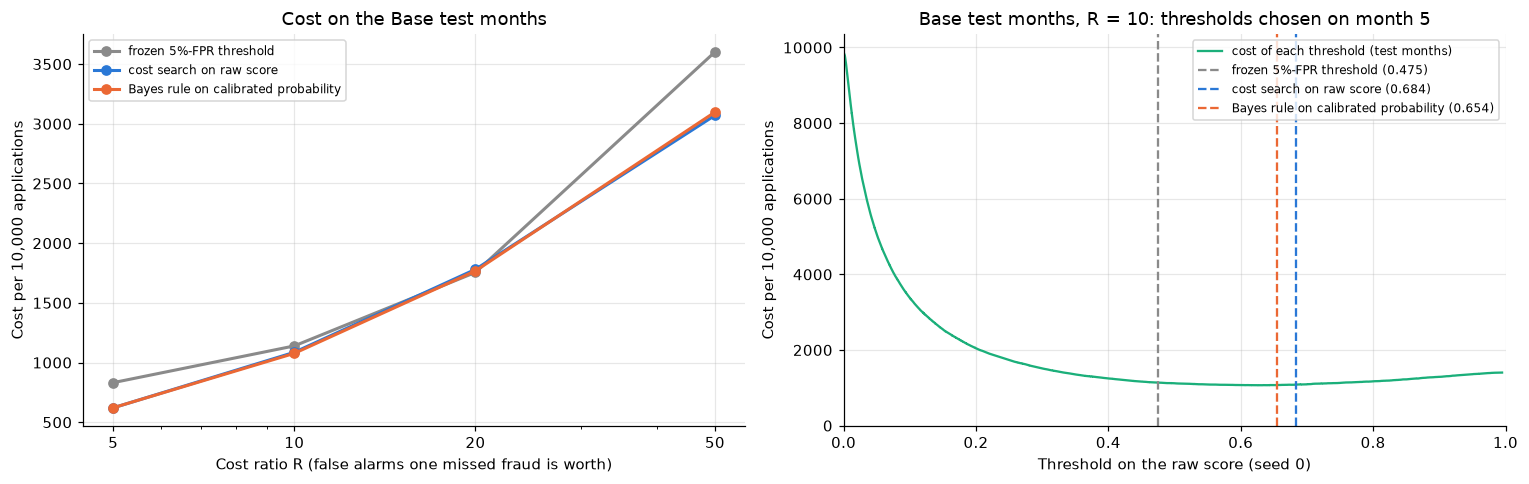

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
RULE_COLOURS = dict(zip(RULES, [GREY, BLUE, ORANGE]))

ax = axes[0]
for rule in RULES:
    values = cost_table.loc['base'].xs(rule, level='rule')['cost per 10,000']
    ax.plot(values.index, values, marker='o', linewidth=2, color=RULE_COLOURS[rule], label=rule)
ax.set_xscale('log')
ax.set_xticks(COST_RATIOS)
ax.set_xticklabels(COST_RATIOS)
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel('Cost ratio R (false alarms one missed fraud is worth)')
ax.set_ylabel('Cost per 10,000 applications')
ax.set_title('Cost on the Base test months')
ax.legend(fontsize=8)

# Cost of every possible threshold on the Base test months, R = 10, seed 0
ax = axes[1]
s = base_test['score_seed0'].to_numpy()
order = np.argsort(-s)
is_fraud = y_base_test[order] == 1
costs = 10_000 * (10 * (is_fraud.sum() - np.cumsum(is_fraud)) + np.cumsum(~is_fraud)) / len(s)
ax.plot(s[order], costs, color=GREEN, linewidth=1.5, label='cost of each threshold (test months)')
markers = {RULES[0]: thresholds[0], RULES[1]: search_thresholds[(10, 0)], RULES[2]: bayes_score_equivalent(0, 10)}
for rule, threshold in markers.items():
    ax.axvline(threshold, color=RULE_COLOURS[rule], linestyle='--', linewidth=1.5, label=f'{rule} ({threshold:.3f})')
ax.set_xlim(0, 1)
ax.set_ylim(0, costs.max() * 1.05)
ax.set_xlabel('Threshold on the raw score (seed 0)')
ax.set_ylabel('Cost per 10,000 applications')
ax.set_title('Base test months, R = 10: thresholds chosen on month 5')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Findings**
- **The cost rules pick very different thresholds from the frozen one.** On month 5 the cost search picks 0.783, 0.681, 0.513 and 0.257 for R = 5, 10, 20 and 50 (mean over seeds), and the Bayes rule's equivalents are 0.786, 0.654, 0.494 and 0.289. The frozen threshold (0.475) is close to the R = 20 choice.
- **They save money when R is not near 20.** On the Base test months the Bayes rule costs 621 per 10,000 applications at R = 5 against 832 for the frozen threshold (25% less), 1,077 against 1,139 at R = 10 (5% less) and 3,098 against 3,602 at R = 50 (14% less). At R = 20 the frozen threshold is slightly cheaper (1,755 against 1,768 and 1,781).
- **The two cost rules give almost the same result** (within 1% of each other on Base for every R), so the calibrated Bayes rule needs no search: one probability cut-off, 1/(1 + R), does the job.
- **On Variants II-V, both cost rules beat the frozen threshold at R = 5, 10 and 20** (on Variant I, at R = 5 and 10), for example at R = 10 on Variants II-V: 980-1,081 for the search and 996-1,089 for the Bayes rule, against 1,269-1,301. At R = 50 the frozen threshold is cheapest on Variants III-V.
- **Cheaper is not fairer.** At R = 10 the Bayes rule flags far fewer people (FPR 2.2% against 5.3%, recall 0.388 against 0.562, precision 0.200 against 0.131), but predictive equality drops from 0.307 to 0.247: the stricter the threshold, the more the remaining false alarms are concentrated on applicants aged 50+. At R = 50 it rises to 0.39, but then 24% of genuine 50+ applicants are flagged.
- The cost curve on the test months is flat near its lowest point, so small differences between thresholds there cost little.

## **10. Shifting Fraud Rates: Which Threshold Rule Holds Up?**
Section 6 showed that the fraud rate and the applicant mix change from month to month and between datasets. Here four rules are compared on Base month 6, Base month 7 and the test months of every variant, at R = 10:

| Rule | How the threshold is set |
|---|---|
| **(i) fixed score threshold** | the frozen threshold, unchanged |
| **(ii) fixed alert rate** | flag the same share of all applications as the frozen threshold flagged in Base month 5 (needs no labels: the top share of each new month's scores) |
| **(iii) Bayes rule (R = 10)** | calibrated probability ≥ 1/11, with the calibrator fitted on Base month 5 |
| **(iv) oracle** | re-picks the 5%-FPR threshold on the evaluated data itself, using its labels. **Not usable in practice** (the labels are only known months later); it is only a ceiling for how well a 5%-FPR rule could do |

Everything in rules (i)-(iii) is chosen on Base month 5 only.

In [36]:
SHIFT_RATIO = 10
SHIFT_RULES = ['(i) fixed score threshold', '(ii) fixed alert rate', '(iii) Bayes rule (R = 10)',
               '(iv) oracle (not usable in practice)']
alert_rates = {seed: (base_month5[f'score_seed{seed}'] >= thresholds[seed]).mean() for seed in SEEDS}
print('Month-5 alert rate of the frozen threshold, per seed:', {seed: round(rate, 4) for seed, rate in alert_rates.items()})

shift_sets = {'base month 6': eval_sets['base month 6'], 'base month 7': eval_sets['base month 7'],
              **{dataset: eval_sets[dataset] for dataset in DATASETS[1:]}}


def shift_flags(rule, seed, y_true, s):
    if rule == SHIFT_RULES[0]:
        return s >= thresholds[seed]
    if rule == SHIFT_RULES[1]:
        k = int(round(alert_rates[seed] * len(s)))
        return s >= np.sort(s)[::-1][k - 1]
    if rule == SHIFT_RULES[2]:
        return calibrators[(CHOSEN_CALIBRATOR, seed)](s) >= 1 / (1 + SHIFT_RATIO)
    if rule == SHIFT_RULES[3]:
        return s >= threshold_at_fpr(y_true, s)
    raise ValueError(rule)


rows = []
for name, part in shift_sets.items():
    y = part['y_true'].to_numpy()
    is_50_plus = part['customer_age'].to_numpy() >= 50
    for seed in SEEDS:
        s = part[f'score_seed{seed}'].to_numpy()
        for rule in SHIFT_RULES:
            rows.append({'data': name, 'rule': rule, 'seed': seed, 'fraud rate': y.mean(),
                         **threshold_results(y, shift_flags(rule, seed, y, s), is_50_plus, SHIFT_RATIO)})
shift_results = pd.DataFrame(rows)
SHIFT_COLUMNS = ['fraud rate', 'FPR', 'recall', 'precision', 'alert rate', 'cost per 10,000']
shift_table = shift_results.groupby(['data', 'rule'], sort=False)[SHIFT_COLUMNS].mean()
shift_table.round(4)

Month-5 alert rate of the frozen threshold, per seed: {0: np.float64(0.0557), 1: np.float64(0.0558), 2: np.float64(0.0556), 3: np.float64(0.0555), 4: np.float64(0.0558)}


fraud rate     FPR  recall  \
data         rule                                                               
base month 6 (i) fixed score threshold                 0.0134  0.0589  0.5614   
             (ii) fixed alert rate                     0.0134  0.0494  0.5212   
             (iii) Bayes rule (R = 10)                 0.0134  0.0243  0.3899   
             (iv) oracle (not usable in practice)      0.0134  0.0498  0.5243   
base month 7 (i) fixed score threshold                 0.0147  0.0467  0.5616   
             (ii) fixed alert rate                     0.0147  0.0480  0.5686   
             (iii) Bayes rule (R = 10)                 0.0147  0.0195  0.3850   
             (iv) oracle (not usable in practice)      0.0147  0.0498  0.5783   
variant_i    (i) fixed score threshold                 0.0140  0.0491  0.5093   
             (ii) fixed alert rate                     0.0140  0.0492  0.5100   
             (iii) Bayes rule (R = 10)                 0.0140  0.0199  0.3281   
             (iv) oracle (not usable in practice)      0.0140  0.0499  0.5136   
variant_ii   (i) fixed score threshold                 0.0140  0.0836  0.6605   
             (ii) fixed alert rate                     0.0140  0.0487  0.5438   
             (iii) Bayes rule (R = 10)                 0.0140  0.0374  0.4873   
             (iv) oracle (not usable in practice)      0.0140  0.0499  0.5505   
variant_iii  (i) fixed score threshold                 0.0110  0.0842  0.5842   
             (ii) fixed alert rate                     0.0110  0.0511  0.4724   
             (iii) Bayes rule (R = 10)                 0.0110  0.0378  0.4062   
             (iv) oracle (not usable in practice)      0.0110  0.0499  0.4676   
variant_iv   (i) fixed score threshold                 0.0110  0.0842  0.5842   
             (ii) fixed alert rate                     0.0110  0.0511  0.4724   
             (iii) Bayes rule (R = 10)                 0.0110  0.0378  0.4062   
             (iv) oracle (not usable in practice)      0.0110  0.0499  0.4676   
variant_v    (i) fixed score threshold                 0.0110  0.0832  0.5934   
             (ii) fixed alert rate                     0.0110  0.0509  0.4878   
             (iii) Bayes rule (R = 10)                 0.0110  0.0372  0.4284   
             (iv) oracle (not usable in practice)      0.0110  0.0498  0.4835   

                                                   precision  alert rate  \
data         rule                                                          
base month 6 (i) fixed score threshold                0.1146      0.0657   
             (ii) fixed alert rate                    0.1254      0.0557   
             (iii) Bayes rule (R = 10)                0.1789      0.0292   
             (iv) oracle (not usable in practice)     0.1251      0.0562   
base month 7 (i) fixed score threshold                0.1527      0.0542   
             (ii) fixed alert rate                    0.1505      0.0557   
             (iii) Bayes rule (R = 10)                0.2282      0.0249   
             (iv) oracle (not usable in practice)     0.1480      0.0576   
variant_i    (i) fixed score threshold                0.1287      0.0555   
             (ii) fixed alert rate                    0.1285      0.0557   
             (iii) Bayes rule (R = 10)                0.1902      0.0242   
             (iv) oracle (not usable in practice)     0.1278      0.0564   
variant_ii   (i) fixed score threshold                0.1011      0.0917   
             (ii) fixed alert rate                    0.1371      0.0557   
             (iii) Bayes rule (R = 10)                0.1564      0.0438   
             (iv) oracle (not usable in practice)     0.1357      0.0569   
variant_iii  (i) fixed score threshold                0.0715      0.0897   
             (ii) fixed alert rate                    0.0931      0.0557   
             (iii) Bayes rule (R = 10)                0.1065      0.0419   
             (iv) oracle

In [37]:
# How much each rule moves across the 7 evaluated sets (smaller = more stable)
spread = shift_table.groupby('rule', sort=False).agg(
    FPR_min=('FPR', 'min'), FPR_max=('FPR', 'max'),
    cost_min=('cost per 10,000', 'min'), cost_max=('cost per 10,000', 'max'),
    cost_mean=('cost per 10,000', 'mean'),
)
spread['FPR range'] = spread['FPR_max'] - spread['FPR_min']
spread['cost range'] = spread['cost_max'] - spread['cost_min']
spread.round(4)

,FPR_min,FPR_max,cost_min,cost_max,cost_mean,FPR range,cost range
rule,,,,,,,
(i) fixed score threshold,0.0467,0.0842,1106.0789,1300.9219,1227.9752,0.0375,194.8430
(ii) fixed alert rate,0.0480,0.0511,1065.5517,1173.2598,1109.4522,0.0031,107.7082
(iii) Bayes rule (R = 10),0.0195,0.0378,995.5229,1139.3395,1061.6846,0.0183,143.8167
(iv) oracle (not usable in practice),0.0498,0.0499,1059.7918,1174.9573,1107.9952,0.0001,115.1655


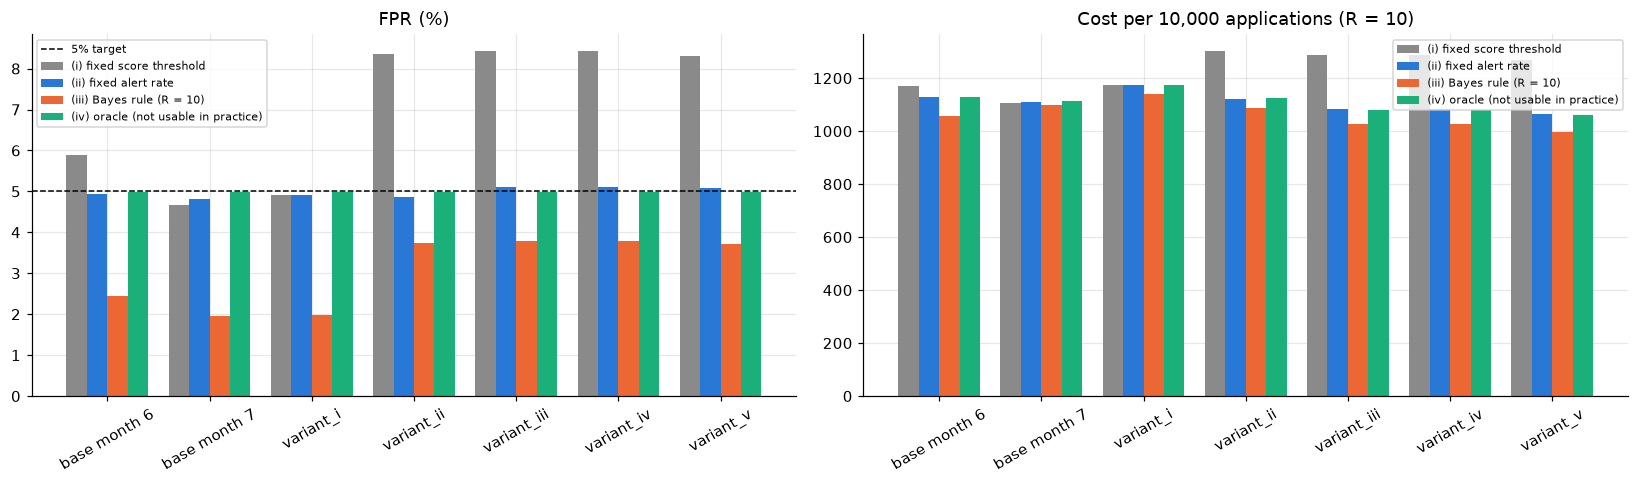

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
names = list(shift_sets)
x = np.arange(len(names))
width = 0.2
SHIFT_COLOURS = dict(zip(SHIFT_RULES, [GREY, BLUE, ORANGE, GREEN]))
for i, rule in enumerate(SHIFT_RULES):
    values = shift_table.xs(rule, level='rule').loc[names]
    axes[0].bar(x + (i - 1.5) * width, values['FPR'] * 100, width, color=SHIFT_COLOURS[rule], label=rule)
    axes[1].bar(x + (i - 1.5) * width, values['cost per 10,000'], width, color=SHIFT_COLOURS[rule], label=rule)
axes[0].axhline(TARGET_FPR * 100, color='black', linestyle='--', linewidth=1, label='5% target')
axes[0].set_title('FPR (%)')
axes[1].set_title('Cost per 10,000 applications (R = 10)')
for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(names, rotation=30)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

**Findings**
- **The fixed score threshold is the least stable.** Its FPR ranges from 4.67% (Base month 7) to 8.42% (Variants III-IV), and its cost at R = 10 from 1,106 to 1,301 per 10,000. On Variants II-V it costs 19-27% more than the Bayes rule.
- **The fixed alert rate keeps the FPR on target.** Flagging the same 5.6% of applications as in month 5 gives an FPR of 4.80-5.11% on every month and dataset, and costs 1,066-1,173 per 10,000 (mean 1,109). That is almost exactly what the oracle achieves (FPR 4.98-4.99%, mean cost 1,108), without needing any labels.
- **The Bayes rule is the cheapest everywhere** (996-1,139 per 10,000, mean 1,062), but it does not aim at an FPR: its FPR moves between 1.95% and 3.78%, higher on Variants II-V, where Platt's probabilities are too high (section 7).
- **So the answer depends on the goal.** To keep the number of wrongly flagged customers (and the review workload) steady, a fixed alert rate holds up best. To keep costs lowest, the Bayes rule does. Both beat leaving the score threshold fixed.
- One caveat for the fixed alert rate: it assumes the share of fraud stays roughly the same (1.10-1.47% here). If fraud doubled, it would still flag only 5.6% of applications and miss more fraud.

## **11. Drift over Time**
How much do the model's inputs and its scores move away from the training months? For Base, months 0-3 (training) are compared with each later month (4-7):
- **PSI (Population Stability Index)** of the score and of every model input after `make_features`, with notebook 02's `psi` function (copied). Usual reading: below 0.1 stable, 0.1-0.25 moderate shift, above 0.25 large shift.
- The **KS statistic** of the score: the largest gap between the two score distributions (0 = identical, 1 = completely separate).

`psi` cuts a numeric column into 10 bins at the training months' deciles. Columns with only 2 values and categorical columns are compared on the share of each value instead (`psi_categories`, the same formula). Missing values are left out of the numeric columns; changes in how often they are missing show up in the `_missing` flags.

The variants' score PSI (months 5-7) is also compared with Base's training months.

In [39]:
def psi(reference, current, bins=10):
    """Copied from notebook 02, section 4.3."""
    edges = np.unique(np.quantile(reference, np.linspace(0, 1, bins + 1)))
    edges[0] = -np.inf
    edges[-1] = np.inf
    ref_pct = pd.cut(reference, edges).value_counts(normalize=True)
    cur_pct = pd.cut(current, edges).value_counts(normalize=True).reindex(ref_pct.index, fill_value=0)
    ref_pct = ref_pct.clip(lower=0.0001)
    cur_pct = cur_pct.clip(lower=0.0001)
    return ((cur_pct - ref_pct) * np.log(cur_pct / ref_pct)).sum()


def psi_categories(reference, current):
    """PSI for a categorical or 0/1 column: the same formula on the share of each value."""
    ref_pct = reference.astype(str).value_counts(normalize=True)
    cur_pct = current.astype(str).value_counts(normalize=True).reindex(ref_pct.index, fill_value=0)
    ref_pct = ref_pct.clip(lower=0.0001)
    cur_pct = cur_pct.clip(lower=0.0001)
    return ((cur_pct - ref_pct) * np.log(cur_pct / ref_pct)).sum()


def psi_level(value):
    return 'stable' if value < 0.1 else ('moderate' if value <= 0.25 else 'large')


LATER_MONTHS = [4, 5, 6, 7]
base_train_scores = scores[(scores['dataset'] == 'base') & scores['month'].isin(TRAIN_MONTHS)]

rows = []
compared = [('base', month) for month in LATER_MONTHS] + [(dataset, month) for dataset in DATASETS[1:] for month in VARIANT_MONTHS]
for dataset, month in compared:
    current = scores[(scores['dataset'] == dataset) & (scores['month'] == month)]
    psis = [psi(base_train_scores[c], current[c]) for c in SCORE_COLUMNS]
    ks = [ks_2samp(base_train_scores[c], current[c]).statistic for c in SCORE_COLUMNS]
    rows.append({'dataset': dataset, 'month': month, 'score PSI (seed 0)': psis[0],
                 'score PSI (mean over seeds)': np.mean(psis), 'level': psi_level(np.mean(psis)),
                 'KS (seed 0)': ks[0], 'KS (mean over seeds)': np.mean(ks)})
score_drift = pd.DataFrame(rows).set_index(['dataset', 'month'])
score_drift.round(4)

score PSI (seed 0)  score PSI (mean over seeds)   level  \
dataset     month                                                            
base        4                  0.0270                       0.0279  stable   
            5                  0.0057                       0.0073  stable   
            6                  0.0084                       0.0102  stable   
            7                  0.0032                       0.0026  stable   
variant_i   5                  0.0039                       0.0050  stable   
            6                  0.0029                       0.0037  stable   
            7                  0.0045                       0.0039  stable   
variant_ii  5                  0.0457                       0.0493  stable   
            6                  0.0631                       0.0676  stable   
            7                  0.0288                       0.0298  stable   
variant_iii 5                  0.0446                       0.0482  stable   
            6                  0.0626                       0.0673  stable   
            7                  0.0260                       0.0271  stable   
variant_iv  5                  0.0442                       0.0477  stable   
            6                  0.0626                       0.0673  stable   
            7                  0.0260                       0.0271  stable   
variant_v   5                  0.0448                       0.0487  stable   
            6                  0.0629                       0.0679  stable   
            7                  0.0261                       0.0271  stable   

                   KS (seed 0)  KS (mean over seeds)  
dataset     month                                     
base        4           0.0665                0.0677  
            5           0.0304                0.0341  
            6           0.0403                0.0444  
            7           0.0218                0.0205  
variant_i   5           0.0205                0.0242  
            6           0.0242                0.0277  
            7           0.0265                0.0246  
variant_ii  5           0.0887                0.0925  
            6           0.1044                0.1082  
            7           0.0684                0.0698  
variant_iii 5           0.0877                0.0916  
            6           0.1042                0.1084  
            7           0.0654                0.0672  
variant_iv  5           0.0872                0.0911  
            6           0.1042                0.1084  
            7           0.0654                0.0672  
variant_v   5           0.0880                0.0925  
            6           0.1057                0.1096  
            7           0.0663                0.0681

In [40]:
# PSI of every model input, Base months 4-7 vs months 0-3
start = time.time()
base_raw = pd.read_csv(f'{DATA_DIR}/{DATASET_FILES["base"]}')
X_base = make_features(base_raw, **FEATURES)
month_of_row = base_raw['month'].to_numpy()
in_train = np.isin(month_of_row, TRAIN_MONTHS)
del base_raw

rows = []
for col in X_base.columns:
    values = X_base[col]
    categorical = isinstance(values.dtype, pd.CategoricalDtype) or values.nunique() <= 2
    if not categorical:
        values = values.replace([np.inf, -np.inf], np.nan)
    reference = values[in_train]
    for month in LATER_MONTHS:
        current = values[month_of_row == month]
        value = psi_categories(reference, current) if categorical else psi(reference.dropna(), current.dropna())
        rows.append({'feature': col, 'month': month, 'PSI': value})
feature_psi = pd.DataFrame(rows).pivot(index='feature', columns='month', values='PSI')
feature_psi = feature_psi.loc[feature_psi.max(axis=1).sort_values(ascending=False).index]
del X_base
print(f'{len(feature_psi)} features, PSI computed in {(time.time() - start) / 60:.1f} min')
print('Features with a large shift (PSI > 0.25) in some month:', list(feature_psi.index[feature_psi.max(axis=1) > 0.25]))
print('Features with a moderate shift (0.1-0.25) at most:',
      list(feature_psi.index[(feature_psi.max(axis=1) >= 0.1) & (feature_psi.max(axis=1) <= 0.25)]))
print('Number of inputs with PSI >= 0.1, by month:', (feature_psi >= 0.1).sum().to_dict())
feature_psi.head(15).round(3)

34 features, PSI computed in 0.1 min
Features with a large shift (PSI > 0.25) in some month: ['date_of_birth_distinct_emails_4w', 'credit_risk_score', 'velocity_24h_vs_4w']
Features with a moderate shift (0.1-0.25) at most: ['name_email_similarity', 'session_length_in_minutes', 'prev_address_months_count', 'proposed_credit_limit', 'bank_branch_count_8w', 'income', 'prev_address_months_count_missing', 'velocity_6h_vs_24h']
Number of inputs with PSI >= 0.1, by month: {4: 1, 5: 5, 6: 8, 7: 5}


month,4,5,6,7
feature,,,,
date_of_birth_distinct_emails_4w,0.089,0.223,0.393,0.574
credit_risk_score,0.122,0.202,0.315,0.355
velocity_24h_vs_4w,0.020,0.080,0.298,0.082
name_email_similarity,0.037,0.195,0.161,0.029
session_length_in_minutes,0.039,0.119,0.044,0.141
prev_address_months_count,0.027,0.094,0.135,0.130
proposed_credit_limit,0.057,0.057,0.129,0.083
bank_branch_count_8w,0.016,0.012,0.021,0.117
income,0.029,0.027,0.109,0.090


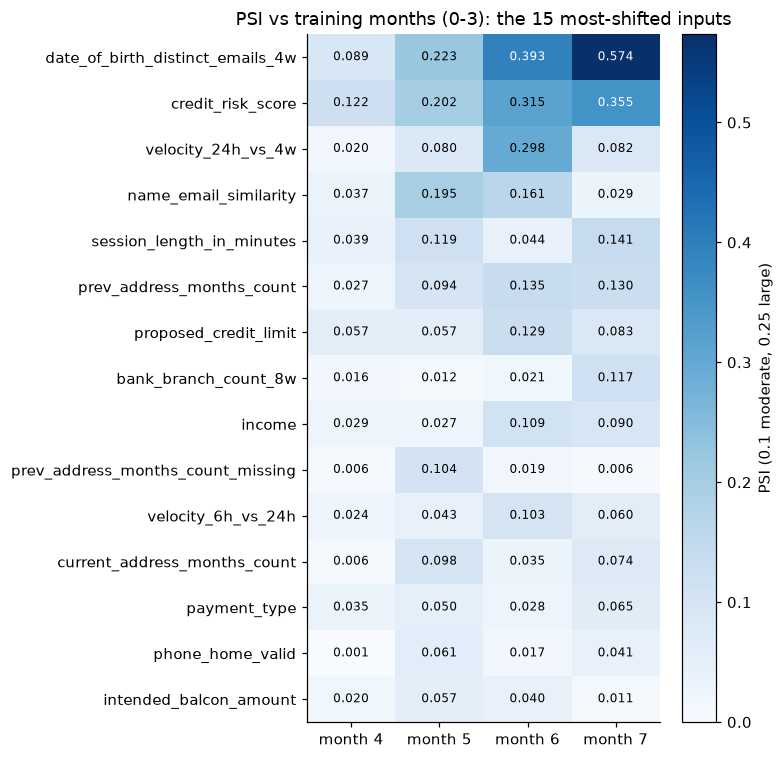

In [41]:
top = feature_psi.head(15)
fig, ax = plt.subplots(figsize=(7, 7))
image = ax.imshow(top.to_numpy(), cmap='Blues', aspect='auto', vmin=0, vmax=max(0.25, top.to_numpy().max()))
for i in range(top.shape[0]):
    for j in range(top.shape[1]):
        value = top.iloc[i, j]
        ax.text(j, i, f'{value:.3f}', ha='center', va='center', fontsize=8,
                color='white' if value > 0.6 * image.get_clim()[1] else 'black')
ax.set_xticks(range(top.shape[1]))
ax.set_xticklabels([f'month {m}' for m in top.columns])
ax.set_yticks(range(top.shape[0]))
ax.set_yticklabels(top.index)
ax.grid(False)
ax.set_title('PSI vs training months (0-3): the 15 most-shifted inputs')
fig.colorbar(image, ax=ax, label='PSI (0.1 moderate, 0.25 large)')
plt.tight_layout()
plt.show()

**Findings**
- **The score distribution barely moves.** Compared with the training months, the score PSI is 0.028, 0.007, 0.010 and 0.003 for Base months 4-7 (mean over seeds), all "stable", and the KS statistic is at most 0.068. Variant I is as stable (PSI at most 0.005). Variants II-V shift more (PSI 0.027-0.068, KS up to 0.110), but still below 0.1.
- **Several inputs do drift.** Three show a large shift: `date_of_birth_distinct_emails_4w` grows steadily (PSI 0.089, 0.223, 0.393, 0.574 for months 4-7), `credit_risk_score` too (0.122 to 0.355), and `velocity_24h_vs_4w` jumps to 0.298 in month 6 only (0.080 and 0.082 in months 5 and 7). Eight more inputs shift moderately in some month.
- **Month 6 is the most disturbed month.** It has the most inputs with PSI of at least 0.1 (8, against 5 in months 5 and 7), including the one-off jump in `velocity_24h_vs_4w`. That fits the month-6 dip in recall at 5% FPR (0.524) and the rise in the frozen threshold's FPR (5.9%) seen in section 6.
- **The score shift lines up with the FPR movement.** Among Base months 4-7, the score PSI ranks the months in the same order as the frozen threshold's FPR: month 4 (PSI 0.028, FPR 7.7%), month 6 (0.010, 5.9%), month 5 (0.007, 5.0%), month 7 (0.003, 4.7%). The threshold sits in the top 6% of scores, so even a shift that PSI calls "stable" moves its FPR. The variants' larger score PSI fits their higher FPR (7.6-8.8%).
- **Input drift does not always hurt.** The largest single shift (`date_of_birth_distinct_emails_4w`, 0.574) is in month 7, the best test month. PSI shows where to look, but it cannot say whether accuracy has dropped; only labels can.

## **12. Customer Groups**
Who does the model wrongly flag, and whose fraud does it miss? On the Base test months, with the frozen threshold (mean over seeds), for groups by:
- **age**: decades (`customer_age` is given as 10, 20, ..., 90). The 50+ vs under 50 comparison is in notebook 06 (section 3 on Base, section 6.1 on every dataset)
- **income**: `income` only takes 9 values (0.1 to 0.9, already decile-like), so each value is one group instead of computed deciles
- **employment_status, housing_status, source, device_os, payment_type**

For each group: size, fraud rate, recall, FPR and precision at the frozen threshold, the group's own recall at 5% FPR (only with at least 50 fraud cases, otherwise n/a), and its FPR divided by the overall FPR (above 1 = wrongly flagged more often than average). Groups with fewer than 1,000 applications are marked unreliable. Nothing is fitted here.

In [42]:
GROUP_VARIABLES = ['age (decade)', 'income', 'employment_status', 'housing_status',
                   'source', 'device_os', 'payment_type']
group_labels = pd.DataFrame({
    'age (decade)': [f'{a}-{a + 9}' for a in base_test['customer_age']],
    'income': base_test['income'].round(1).map('{:.1f}'.format).to_numpy(),
    **{col: base_test[col].astype(str).to_numpy() for col in GROUP_VARIABLES[2:]},
})

fraud = y_base_test == 1
genuine = ~fraud
flags_by_seed = {seed: base_test[f'score_seed{seed}'].to_numpy() >= thresholds[seed] for seed in SEEDS}
overall_fpr = {seed: flags_by_seed[seed][genuine].mean() for seed in SEEDS}

rows = []
for variable in GROUP_VARIABLES:
    for group, positions in group_labels.groupby(variable).indices.items():
        in_group = np.zeros(len(base_test), dtype=bool)
        in_group[positions] = True
        n_fraud = (in_group & fraud).sum()
        for seed in SEEDS:
            f = flags_by_seed[seed]
            s = base_test[f'score_seed{seed}'].to_numpy()
            fpr = f[in_group & genuine].mean()
            rows.append({
                'variable': variable, 'group': group, 'seed': seed,
                'applications': in_group.sum(), 'fraud cases': n_fraud, 'fraud rate': n_fraud / in_group.sum(),
                'recall': f[in_group & fraud].mean() if n_fraud > 0 else np.nan,
                'FPR': fpr,
                'precision': y_base_test[in_group & f].mean() if (in_group & f).any() else np.nan,
                'recall@5%FPR in group': recall_at_fpr(y_base_test[in_group], s[in_group]) if n_fraud >= 50 else np.nan,
                'FPR / overall FPR': fpr / overall_fpr[seed],
            })
group_results = pd.DataFrame(rows)
group_table = group_results.drop(columns='seed').groupby(['variable', 'group'], sort=False).mean()
group_table[['applications', 'fraud cases']] = group_table[['applications', 'fraud cases']].astype(int)
group_table['note'] = np.where(group_table['applications'] < 1000, 'unreliable (< 1,000 rows)', '')

shown = group_table.round(4).astype(object)
shown['recall@5%FPR in group'] = shown['recall@5%FPR in group'].where(group_table['recall@5%FPR in group'].notna(), 'n/a')
shown

applications fraud cases fraud rate  recall  \
variable          group                                                   
age (decade)      10-19             5096          22     0.0043  0.1909   
                  20-29            46341         309     0.0067  0.3269   
                  30-39            63322         714     0.0113  0.4591   
                  40-49            56473         844     0.0149  0.5818   
                  50-59            25676         630     0.0245  0.6724   
                  60-69             6464         277     0.0429  0.7386   
                  70-79             1339          68     0.0508  0.7471   
                  80-89              284          14     0.0493  0.9286   
                  90-99               16           0        0.0     NaN   
income            0.1              22600         161     0.0071  0.3602   
                  0.2              11277          77     0.0068  0.4857   
                  0.3               8528          71     0.0083  0.4592   
                  0.4              14562         136     0.0093  0.4618   
                  0.5              10254          94     0.0092  0.3383   
                  0.6              22025         237     0.0108  0.4574   
                  0.7              22189         220     0.0099  0.4545   
                  0.8              34359         396     0.0115  0.5404   
                  0.9              59217        1486     0.0251  0.6534   
employment_status CA              158709        2413     0.0152  0.5749   
                  CB               22838         216     0.0095  0.4009   
                  CC                6511         202      0.031  0.6673   
                  CD                4517          13     0.0029  0.3538   
                  CE                4550          15     0.0033  0.1333   
                  CF                7805          17     0.0022  0.0471   
                  CG                  81           2     0.0247     0.0   
housing_status    BA               39900        1786     0.0448  0.7234   
                  BB               56375         388     0.0069  0.3134   
                  BC               70264         495      0.007  0.3168   
                  BD                8205          70     0.0085    0.42   
                  BE               29926         138     0.0046  0.1116   
                  BF                 311           1     0.0032     0.8   
                  BG                  30           0        0.0     NaN   
source            INTERNET        203700        2846      0.014  0.5618   
                  TELEAPP           1311          32     0.0244  0.5312   
device_os         linux            65032         481     0.0074  0.3505   
                  macintosh        10815         208     0.0192  0.5462   
                  other            77301         568     0.0073  0.3507   
                  windows          50581        1602     0.0317  0.7006   
                  x11               1282          19     0.0148  0.6421   
payment_type      AA               49329         316     0.0064   0.331   
                  AB               82372        1173     0.0142   0.532   
                  AC               53492        1075     0.0201  0.6811   
                  AD               19777         314     0.0159  0.4943   
                  AE                  41           0        0.0     NaN   

                                FPR precision recall@5%FPR in group  \
variable          group                                               
age (decade)      10-19      0.0098    0.0774                   n/a   
                  20-29       0.017    0.1145                0.5243   
                  30-39      0.0381    0.1209                0.5106   
                  40-49      0.0606    0.1271                0.5393   
                  50-59      0.1143    0.1289                 0.499   
                  60-69        0.16    0.1713                0.4823   
         

**Bootstrap CIs** for the FPR and recall of the age-decade, income and employment groups: Poisson weights as in section 5 (1,000 resamples, the same resampled applications for every seed, averaged over seeds). Group FPR and recall are ratios of weighted counts, so this is a matrix product per batch.

In [43]:
CI_VARIABLES = ['age (decade)', 'income', 'employment_status']


def bootstrap_group_rates(masks, n_resamples=N_BOOTSTRAP, rng_seed=BOOTSTRAP_SEED, batch=50):
    """FPR and recall of each group (mask) at the frozen threshold, averaged over seeds, on Poisson resamples."""
    G = len(masks)
    totals = np.column_stack([m & genuine for m in masks] + [m & fraud for m in masks]).astype(np.float32)
    flagged = [np.column_stack([m & genuine & f for m in masks] + [m & fraud & f for m in masks]).astype(np.float32)
               for f in flags_by_seed.values()]
    rng = np.random.default_rng(rng_seed)
    fpr, recall = [], []
    for start in range(0, n_resamples, batch):
        w = rng.poisson(1.0, size=(min(batch, n_resamples - start), len(y_base_test))).astype(np.float32)
        group_totals = w @ totals
        with np.errstate(divide='ignore', invalid='ignore'):
            rates = np.mean([(w @ f) / group_totals for f in flagged], axis=0)
        fpr.append(rates[:, :G])
        recall.append(rates[:, G:])
    return np.vstack(fpr), np.vstack(recall)


start = time.time()
ci_groups = [(variable, group) for variable in CI_VARIABLES for group in group_table.loc[variable].index]
masks = [group_labels[variable].to_numpy() == group for variable, group in ci_groups]
fpr_resamples, recall_resamples = bootstrap_group_rates(masks)
print(f'Group bootstrap in {(time.time() - start) / 60:.1f} min')

import warnings
with warnings.catch_warnings():
    warnings.simplefilter('ignore', RuntimeWarning)   # age 90-99 has no fraud cases, so no recall
    group_ci = pd.DataFrame({
        'FPR': [group_table.loc[key, 'FPR'] for key in ci_groups],
        'FPR CI low': np.nanpercentile(fpr_resamples, 2.5, axis=0),
        'FPR CI high': np.nanpercentile(fpr_resamples, 97.5, axis=0),
        'recall': [group_table.loc[key, 'recall'] for key in ci_groups],
        'recall CI low': np.nanpercentile(recall_resamples, 2.5, axis=0),
        'recall CI high': np.nanpercentile(recall_resamples, 97.5, axis=0),
        'note': [group_table.loc[key, 'note'] for key in ci_groups],
    }, index=pd.MultiIndex.from_tuples(ci_groups, names=['variable', 'group']))
group_ci.round(4)

Group bootstrap in 0.1 min


FPR  FPR CI low  FPR CI high  recall  \
variable          group                                            
age (decade)      10-19  0.0098      0.0073       0.0124  0.1909   
                  20-29  0.0170      0.0158       0.0182  0.3269   
                  30-39  0.0381      0.0366       0.0395  0.4591   
                  40-49  0.0606      0.0587       0.0626  0.5818   
                  50-59  0.1143      0.1104       0.1183  0.6724   
                  60-69  0.1600      0.1515       0.1691  0.7386   
                  70-79  0.1868      0.1666       0.2064  0.7471   
                  80-89  0.2074      0.1614       0.2547  0.9286   
                  90-99  0.3625      0.1429       0.6002     NaN   
income            0.1    0.0187      0.0170       0.0203  0.3602   
                  0.2    0.0218      0.0192       0.0244  0.4857   
                  0.3    0.0258      0.0225       0.0289  0.4592   
                  0.4    0.0258      0.0233       0.0283  0.4618   
                  0.5    0.0300      0.0271       0.0331  0.3383   
                  0.6    0.0351      0.0327       0.0378  0.4574   
                  0.7    0.0385      0.0361       0.0412  0.4545   
                  0.8    0.0508      0.0487       0.0530  0.5404   
                  0.9    0.1013      0.0989       0.1036  0.6534   
employment_status CA     0.0589      0.0578       0.0600  0.5749   
                  CB     0.0279      0.0259       0.0300  0.4009   
                  CC     0.1258      0.1176       0.1346  0.6673   
                  CD     0.0119      0.0091       0.0149  0.3538   
                  CE     0.0048      0.0032       0.0068  0.1333   
                  CF     0.0029      0.0019       0.0041  0.0471   
                  CG     0.0506      0.0060       0.0969  0.0000   

                         recall CI low  recall CI high  \
variable          group                                  
age (decade)      10-19         0.0476          0.3600   
                  20-29         0.2729          0.3796   
                  30-39         0.4237          0.4939   
                  40-49         0.5475          0.6131   
                  50-59         0.6366          0.7064   
                  60-69         0.6885          0.7848   
                  70-79         0.6393          0.8339   
                  80-89         0.7643          1.0000   
                  90-99            NaN             NaN   
income            0.1           0.2843          0.4310   
                  0.2           0.3806          0.6032   
                  0.3           0.3460          0.5733   
                  0.4           0.3819          0.5521   
                  0.5           0.2540          0.4269   
                  0.6           0.3935          0.5168   
                  0.7           0.3937          0.5125   
                  0.8           0.4918          0.5908   
                  0.9           0.6297          0.6764   
employment_status CA            0.5548          0.5936   
                  CB            0.3385          0.4645   
                  CC            0.6009          0.7287   
                  CD            0.1090          0.6365   
                  CE            0.0000          0.3529   
                  CF            0.0000          0.1500   
                  CG            0.0000          0.0000   

                                              note  
variable          group                             
age (decade)      10-19                             
                  20-29                             
                  30-39                             
                  40-49                             
                  50-59                             
                  60-69                             
                  70-79                             
                  80-89  unreliable (< 1,000 rows)  
                  90-99  unreliable (< 1,000 rows)  
income            0.1                    

**Are high FPRs explained by high fraud rates?** If the model simply flags groups where fraud is more common, a group's FPR should rise with its fraud rate. The Spearman rank correlation across all reliable groups (at least 1,000 rows) measures this.

In [44]:
reliable = group_table[(group_table['applications'] >= 1000)]
rho, p_value = spearmanr(reliable['fraud rate'], reliable['FPR'])
print(f'{len(reliable)} reliable groups: Spearman correlation between fraud rate and FPR = {rho:.2f} (p = {p_value:.2g})')
reliable.sort_values('FPR / overall FPR', ascending=False)[['applications', 'fraud rate', 'FPR', 'FPR / overall FPR', 'recall']].head(8).round(4)

38 reliable groups: Spearman correlation between fraud rate and FPR = 0.98 (p = 4.6e-26)


applications  fraud rate     FPR  \
variable          group                                       
housing_status    BA              39900      0.0448  0.2078   
age (decade)      70-79            1339      0.0508  0.1868   
                  60-69            6464      0.0429  0.1600   
device_os         windows         50581      0.0317  0.1374   
employment_status CC               6511      0.0310  0.1258   
age (decade)      50-59           25676      0.0245  0.1143   
income            0.9             59217      0.0251  0.1013   
payment_type      AC              53492      0.0201  0.0849   

                           FPR / overall FPR  recall  
variable          group                               
housing_status    BA                  3.9115  0.7234  
age (decade)      70-79               3.5153  0.7471  
                  60-69               3.0116  0.7386  
device_os         windows             2.5865  0.7006  
employment_status CC                  2.3681  0.6673  
age (decade)      50-59               2.1518  0.6724  
income            0.9                 1.9058  0.6534  
payment_type      AC                  1.5981  0.6811

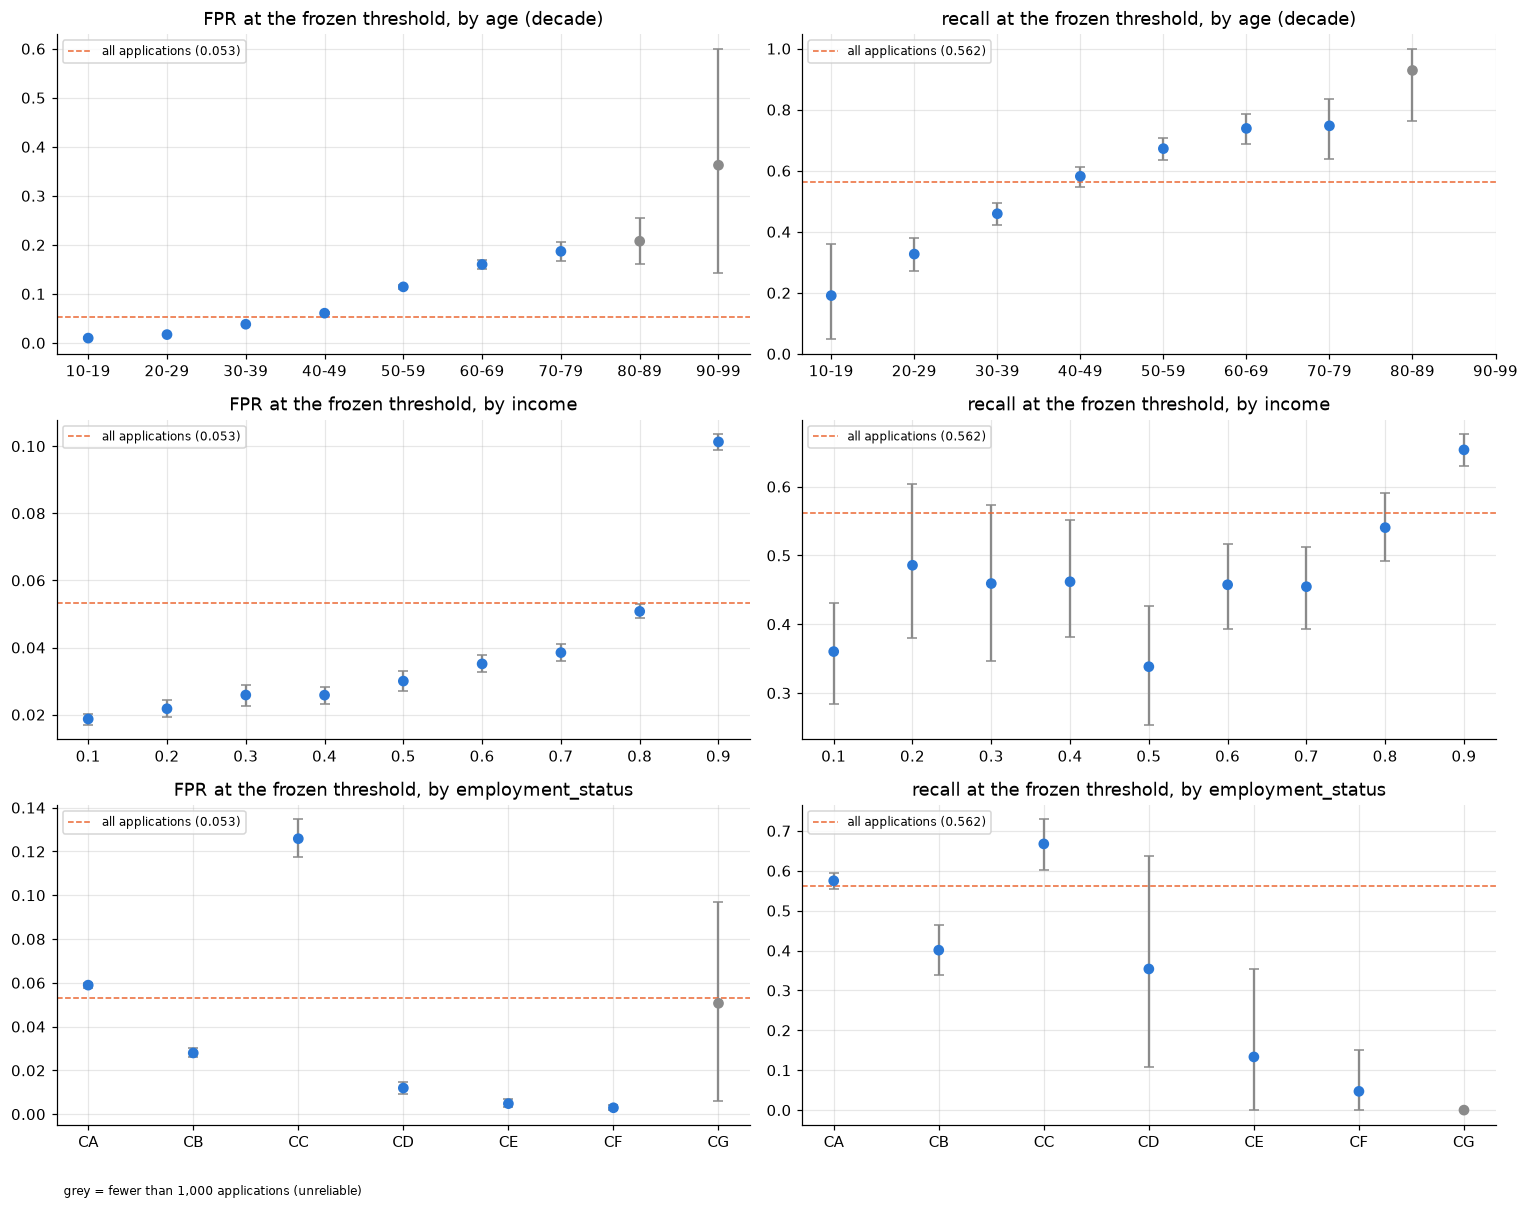

In [45]:
fig, axes = plt.subplots(3, 2, figsize=(14, 11))
for row, variable in enumerate(['age (decade)', 'income', 'employment_status']):
    part = group_ci.loc[variable]
    x = np.arange(len(part))
    colours = [GREY if note else BLUE for note in part['note']]
    for col, (metric, overall) in enumerate([('FPR', np.mean(list(overall_fpr.values()))),
                                             ('recall', TPR_TEST)]):
        ax = axes[row, col]
        ax.errorbar(x, part[metric], yerr=[part[metric] - part[f'{metric} CI low'], part[f'{metric} CI high'] - part[metric]],
                    fmt='none', ecolor=GREY, capsize=3)
        ax.scatter(x, part[metric], color=colours, zorder=3)
        ax.axhline(overall, color=ORANGE, linestyle='--', linewidth=1, label=f'all applications ({overall:.3f})')
        ax.set_xticks(x)
        ax.set_xticklabels(part.index)
        ax.set_title(f'{metric} at the frozen threshold, by {variable}')
        ax.legend(fontsize=8, loc='upper left')
axes[2, 0].annotate('grey = fewer than 1,000 applications (unreliable)', xy=(0.01, -0.22), xycoords='axes fraction', fontsize=8)
plt.tight_layout()
plt.show()

**Findings**
- **Older applicants are wrongly flagged most.** The FPR rises with every decade: 1.0% (10-19), 1.7% (20-29), 3.8% (30-39), 6.1% (40-49), 11.4% (50-59), 16.0% (60-69) and 18.7% (70-79). 60-69 year olds are flagged 3.0 times as often as the average applicant. (The 50+ vs under 50 rates, with intervals, are in section 5; notebook 06 analyses that gap.)
- **Other groups flagged far more than average:** housing status BA (FPR 20.8%, 3.9 times the average), Windows devices (13.7%, 2.6 times), employment status CC (12.6%, 2.4 times) and the highest income value, 0.9 (10.1%, 1.9 times).
- **This is almost entirely explained by group fraud rates.** Across the 38 reliable groups, the FPR follows the fraud rate almost perfectly (Spearman correlation 0.98). The groups above all have more fraud than average: 4.5% for BA, 3.2% for Windows, 3.1% for CC, 2.5% for income 0.9, and 4.3-5.1% for ages 60-79, against 1.40% overall.
- **Fraud is also caught more often in these groups.** At the frozen threshold, recall rises with age from 0.33 (20-29) to 0.67 (50-59) and 0.74-0.75 (60-79), and is 0.72 for housing status BA, 0.67 for employment status CC and 0.65 for income 0.9, against 0.56 overall. The gaps come from using one threshold for groups with very different fraud rates; notebook 06 (section 3) compares the 50+ and under-50 groups in detail, including how well the model ranks each.
- **Explained is not the same as fair.** A genuine 60-69 year old is still about 3 times as likely to be wrongly flagged as the average genuine applicant, through no fault of their own. Predictive equality is 0.31 on every dataset (section 4), and the bank would have to decide whether that is acceptable.
- Six groups have fewer than 1,000 applications (ages 80-89 and 90-99, CG, BF, BG and AE) and are marked unreliable; their numbers, and their very wide CIs, should not be read closely.

## **13. Summary**

### What we did
We took the frozen final model from notebook 02 (XGBoost, 5 seeds) and, without changing it, measured how sure we can be of its test results, how it behaves from month to month, how to turn its scores into probabilities and decisions, and whom it wrongly flags. Only Base month 5 was used to fit or choose anything here; months 6-7 were only used to evaluate.

### Headline results
1. **On the Base test months, the model ranks well: recall at 5% FPR is 0.548** (95% CI 0.529-0.566; ROC-AUC 0.894, CI 0.888-0.899). With its frozen threshold it catches 56.2% of fraud (recall, CI 54.4-57.9%) while wrongly flagging 5.3% of genuine applicants. The random seed hardly matters (standard deviation 0.002); which applications land in the test set matters about 10 times more.
2. **It does equally well on Variant II (0.551, CI 0.533-0.569) and clearly worse on Variants III-V (0.468-0.483, CIs within 0.449-0.502).**
3. **Performance does not steadily decline over time.** Recall at 5% FPR is 0.543, 0.524 and 0.578 in months 5, 6 and 7; month 6 is the weakest and also the month in which the most model inputs drift (8 inputs with PSI of at least 0.1).
4. **The frozen score threshold does not keep its 5% FPR.** It flags 5.9% of genuine applicants in month 6, 4.7% in month 7 and 8.3-8.4% on Variants II-V. Flagging a fixed share of applications instead (5.6%) keeps the FPR at 4.8-5.1% everywhere.
5. **Platt calibration turns scores into honest probabilities on Base** (ECE 0.0015, CI 0.0011-0.0021, against 0.110 for the raw scores), but it predicts about a fifth too little fraud in month 7 and 27-56% too much on Variants II-V.
6. **Precision depends heavily on the fraud rate.** With the frozen threshold, 13.1% of flagged applications are fraud on the Base test months (CI 12.5-13.6%), but at a fraud rate of 0.1% it would be 1.05%, about 95 false alarms per fraud caught.
7. **A cost-based threshold is cheaper.** If one missed fraud is worth 10 false alarms, flagging when the Platt probability is at least 1/11 costs 1,077 per 10,000 applications against 1,139 for the frozen threshold (5% less), and 25% less when a missed fraud is worth 5.
8. **Genuine applicants aged 50+ are wrongly flagged 3.3 times as often** as those under 50 (12.7%, CI 12.3-13.0%, against 3.9%, CI 3.8-4.0%; predictive equality 0.31, CI 0.30-0.32; section 5). Across all customer groups, a group's FPR follows its fraud rate almost exactly (Spearman correlation 0.98, section 12). Notebook 06 analyses the age gap.

### What this means for deploying the model
- **Calibrator: Platt**, refitted on the latest labelled month. It never changes the ranking, it was the best on both month 5 and the test months, and it needs only two numbers per seed. Correct its probabilities with the prior shift (section 8.1) when the fraud rate is known to have moved.
- **Threshold rule: it depends on what the bank wants to keep steady.** If the bank can state how many false alarms a missed fraud is worth, use the **Bayes rule on Platt probabilities** (flag if p ≥ 1/(1 + R)): it was the cheapest rule on every month and dataset. If the priority is a steady review workload and a steady share of wrongly flagged customers, use a **fixed alert rate**, which matched the oracle's FPR without any labels. Either way, **do not leave the score threshold fixed**: it was the least stable and the most expensive on the variants.
- **Monitor every month**: the score PSI and the input PSI (cheap, no labels needed), the alert rate, and, once labels arrive, the FPR for 50+ and under 50.
- **Fairness needs a decision, not just a number.** The age gap is explained by fraud rates, but genuine older applicants still pay for it. The cost-based thresholds make the ratio worse (predictive equality 0.25 at R = 10), so a bank that cares about it may need group-aware review or a cap on the FPR of each age group.

### Limitations
- **Synthetic data.** BAF is generated to resemble real bank applications, but it is not real; real fraud rates, drift and group differences will differ.
- **Some choices were checked on test data.** Platt was chosen on the Base test months (month 5 alone agreed), and the comparisons of rules in sections 9-10 use the test months, so the reported savings are slightly optimistic.
- **One model family.** Only the frozen XGBoost model was evaluated; another model could be calibrated or drift differently.
- **Assumed costs.** The cost ratios (5-50) are assumptions, and the cost of an analyst's time is not included.
- **One month to fit on.** Everything is fitted on Base month 5 (119,323 applications); the month-to-month swings in section 6 show that a single month is a noisy guide.
- **Fairness is only checked for age** (and descriptively for the other groups), with the groups the dataset provides.

### What the next notebooks take from here
- **Notebook 06** analyses the age gap (predictive equality 0.31) in depth, building on the customer groups of section 12.
- **Notebook 07** (the final system) reuses two methods chosen here, Platt calibration (section 7.3) and a fixed alert rate (section 10), refitted for its reweighed model.